In [1]:
from pathlib import Path

ROOT = Path("/kaggle/input/datasets")

print("DATASET INVENTORY")
print("=" * 60)

for dataset in ROOT.iterdir():

    print("\nDATASET:", dataset.name)

    for path in dataset.rglob("*"):

        if path.is_file() and (
            path.suffix.lower() in [".csv", ".zip", ".txt"]
        ):
            print(path.relative_to(dataset))

DATASET INVENTORY

DATASET: arjav007

DATASET: babulkumar07
lungvision-nih-expert-labels/nih-cxr-14_labels_all_findings_expert_labels_test_individual_readers.csv
lungvision-nih-expert-labels/nih-cxr-14_labels_all_findings_expert_labels_test_labels.csv
lungvision/LungVision_AI_Model_Registry/configuration/checksums.csv
lungvision/LungVision_AI_Model_Registry/experiment_reports/blur_robustness_metrics.csv
lungvision/LungVision_AI_Model_Registry/experiment_reports/image_quality_audit.csv
lungvision/LungVision_AI_Model_Registry/experiment_reports/individual_occlusion_summary.csv
lungvision/LungVision_AI_Model_Registry/experiment_reports/occlusion_analysis_results.csv
lungvision/LungVision_AI_Model_Registry/experiment_reports/probability_shift_statistics.csv
lungvision/LungVision_AI_Model_Registry/experiment_reports/spatial_audit_comparison.csv
lungvision/LungVision_AI_Model_Registry/experiment_reports/spatial_position_control.csv
lungvision/LungVision_AI_Model_Registry/test_results/origina

In [2]:
# ============================================================
# CELL 28.4: NIH CHEST X-RAY DATASET AUDIT
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter
from PIL import Image

ROOT = Path(
    "/kaggle/input/datasets/nih-chest-xrays"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/nih_external_audit"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. COMPLETE FILE INVENTORY
# ------------------------------------------------------------

files = [
    p for p in ROOT.rglob("*")
    if p.is_file()
]

extension_counts = Counter(
    p.suffix.lower() for p in files
)

print("=" * 65)
print("NIH CHEST X-RAY DATASET AUDIT")
print("=" * 65)

print("\nTotal files:", len(files))
print("\nFile extensions:")

for ext, count in extension_counts.items():
    print(ext or "No extension", count)

# ------------------------------------------------------------
# 2. LOCATE IMAGE FILES
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg"
}

image_paths = [
    p for p in files
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

print("\nTotal images:", len(image_paths))

for path in image_paths[:10]:
    print(path.relative_to(ROOT))

# ------------------------------------------------------------
# 3. LOCATE LABEL CSV FILES
# ------------------------------------------------------------

label_files = [
    p for p in files
    if p.name.lower() == "sample_labels.csv"
]

if not label_files:
    raise FileNotFoundError(
        "sample_labels.csv not found."
    )

print("\nLabel CSV files found:", len(label_files))

for p in label_files:
    print(p)

# Use the CSV with the largest number of records
csv_info = []

for path in label_files:

    temp = pd.read_csv(path)

    csv_info.append({
        "path": path,
        "rows": len(temp),
        "columns": temp.columns.tolist()
    })

    print("\nCSV:", path)
    print("Rows:", len(temp))
    print("Columns:", temp.columns.tolist())

csv_info.sort(
    key=lambda x: x["rows"],
    reverse=True
)

CSV_PATH = csv_info[0]["path"]

df = pd.read_csv(CSV_PATH)

print("\nSelected CSV:", CSV_PATH)

# ------------------------------------------------------------
# 4. VERIFY REQUIRED METADATA
# ------------------------------------------------------------

required_columns = [
    "Image Index",
    "Finding Labels",
    "Patient ID",
    "View Position"
]

missing_columns = [
    c for c in required_columns
    if c not in df.columns
]

if missing_columns:
    raise ValueError(
        "Required metadata missing: "
        + str(missing_columns)
    )

print("\nRequired metadata columns verified.")

# ------------------------------------------------------------
# 5. CHECK IMAGE MAPPING
# ------------------------------------------------------------

image_lookup = {}

for path in image_paths:

    image_lookup.setdefault(
        path.name.lower(),
        path
    )

    image_lookup.setdefault(
        path.stem.lower(),
        path
    )

df["resolved_image_path"] = df[
    "Image Index"
].astype(str).apply(
    lambda x: str(
        image_lookup.get(
            x.lower(),
            image_lookup.get(Path(x).stem.lower(), None)
        )
    ) if (
        image_lookup.get(x.lower())
        or image_lookup.get(Path(x).stem.lower())
    ) else None
)

resolved_count = df["resolved_image_path"].notna().sum()

print("\nIMAGE MAPPING")
print("Label records:", len(df))
print("Images matched:", resolved_count)
print("Images missing:", len(df) - resolved_count)
print("Unique image names:", df["Image Index"].nunique())

# ------------------------------------------------------------
# 6. LABEL DISTRIBUTION
# ------------------------------------------------------------

print("\nFINDING LABEL DISTRIBUTION")

print(
    df["Finding Labels"]
    .value_counts()
    .head(20)
)

# Create binary labels
# No Finding = 0
# Any reported finding = 1

df["external_label"] = np.where(
    df["Finding Labels"].astype(str).str.strip() == "No Finding",
    0,
    1
)

print("\nBINARY LABEL DISTRIBUTION")

print(
    df["external_label"]
    .value_counts()
    .rename({
        0: "Normal",
        1: "Abnormal"
    })
)

# ------------------------------------------------------------
# 7. VIEW POSITION DISTRIBUTION
# ------------------------------------------------------------

df["View Position"] = (
    df["View Position"]
    .astype(str)
    .str.strip()
    .str.upper()
)

print("\nVIEW POSITION DISTRIBUTION")

print(
    df["View Position"]
    .value_counts(dropna=False)
)

# Select frontal images
frontal = df[
    df["View Position"].isin(["PA", "AP"])
].copy()

pa = df[
    df["View Position"] == "PA"
].copy()

print("\nFRONTAL COHORT")
print("AP + PA:", len(frontal))
print("PA only:", len(pa))

print("\nFrontal label counts:")

print(
    frontal["external_label"]
    .value_counts()
    .rename({
        0: "Normal",
        1: "Abnormal"
    })
)

# ------------------------------------------------------------
# 8. PATIENT-LEVEL AUDIT
# ------------------------------------------------------------

print("\nPATIENT-LEVEL INFORMATION")

df["Patient ID"] = pd.to_numeric(
    df["Patient ID"],
    errors="coerce"
)

print(
    "Unique patients:",
    df["Patient ID"].nunique()
)

print(
    "Patients with multiple images:",
    int(
        (df.groupby("Patient ID").size() > 1).sum()
    )
)

# Duplicate patient-image pairs
print(
    "Duplicate patient-image pairs:",
    df.duplicated(
        ["Patient ID", "Image Index"]
    ).sum()
)

# ------------------------------------------------------------
# 9. CHECK IMAGE READABILITY
# ------------------------------------------------------------

readable = 0
unreadable = []

for path in frontal["resolved_image_path"].dropna():

    try:
        with Image.open(path) as img:
            img.verify()

        readable += 1

    except Exception:
        unreadable.append(path)

print("\nIMAGE INTEGRITY")
print("Frontal images:", len(frontal))
print("Readable:", readable)
print("Unreadable:", len(unreadable))

# ------------------------------------------------------------
# 10. CREATE EXTERNAL VALIDATION MANIFEST
# ------------------------------------------------------------

frontal["Patient ID"] = frontal[
    "Patient ID"
].astype("Int64")

frontal_manifest = frontal[
    frontal["resolved_image_path"].notna()
    & frontal["Patient ID"].notna()
].copy()

frontal_manifest = frontal_manifest[
    frontal_manifest["resolved_image_path"].apply(
        lambda p: p not in unreadable
    )
].copy()

# Primary cohort: PA views only, matching the IN-CXR
# PA projection. Keep all patients, including repeated
# images, so we can report and assess clustering.
pa_manifest = frontal_manifest[
    frontal_manifest["View Position"] == "PA"
].copy()

# Save both cohorts
frontal_manifest.to_csv(
    OUTPUT_DIR / "nih_ap_pa_external_manifest.csv",
    index=False
)

pa_manifest.to_csv(
    OUTPUT_DIR / "nih_pa_external_manifest.csv",
    index=False
)

print("\n" + "=" * 65)
print("NIH DATASET AUDIT COMPLETED")
print("=" * 65)

print("Total images:", len(image_paths))
print("Label records:", len(df))
print("Matched records:", resolved_count)
print("AP/PA cohort:", len(frontal_manifest))
print("PA-only cohort:", len(pa_manifest))
print("PA-only unique patients:", pa_manifest["Patient ID"].nunique())

print("\nSaved:")
print(OUTPUT_DIR / "nih_ap_pa_external_manifest.csv")
print(OUTPUT_DIR / "nih_pa_external_manifest.csv")

NIH CHEST X-RAY DATASET AUDIT

Total files: 11214

File extensions:
.csv 2
.png 11212

Total images: 11212
sample/sample/images/00000013_005.png
sample/sample/images/00000013_026.png
sample/sample/images/00000017_001.png
sample/sample/images/00000030_001.png
sample/sample/images/00000032_001.png
sample/sample/images/00000040_003.png
sample/sample/images/00000042_002.png
sample/sample/images/00000057_001.png
sample/sample/images/00000061_002.png
sample/sample/images/00000061_019.png

Label CSV files found: 2
/kaggle/input/datasets/nih-chest-xrays/sample/sample_labels.csv
/kaggle/input/datasets/nih-chest-xrays/sample/sample/sample_labels.csv

CSV: /kaggle/input/datasets/nih-chest-xrays/sample/sample_labels.csv
Rows: 5606
Columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImageWidth', 'OriginalImageHeight', 'OriginalImagePixelSpacing_x', 'OriginalImagePixelSpacing_y']

CSV: /kaggle/input/datasets/nih-chest-xra

In [3]:
# ============================================================
# CELL 28.5: NIH EXTERNAL VALIDATION
# Original vs Blur-Augmented ResNet18
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 0
BOOTSTRAP_REPS = 300

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NIH_ROOT = Path(
    "/kaggle/input/datasets/nih-chest-xrays"
)

REGISTRY_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/lungvision"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "nih_external_validation"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Previously selected on IN-CXR validation.
# Do not recalibrate on NIH.
LOCKED_THRESHOLDS = {
    "Original ResNet18": 0.1765,
    "Blur-Augmented ResNet18": 0.1879
}

print("=" * 65)
print("LUNGVISION AI | NIH EXTERNAL VALIDATION")
print("=" * 65)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. LOAD NIH METADATA
# ------------------------------------------------------------

csv_paths = list(
    NIH_ROOT.rglob("sample_labels.csv")
)

if not csv_paths:
    raise FileNotFoundError(
        "NIH sample_labels.csv not found."
    )

csv_candidates = [
    (path, pd.read_csv(path))
    for path in csv_paths
]

csv_candidates.sort(
    key=lambda x: len(x[1]),
    reverse=True
)

CSV_PATH, nih_df = csv_candidates[0]

# Check whether duplicated CSV copies are identical
for other_path, other_df in csv_candidates[1:]:

    if not nih_df.equals(other_df):
        raise ValueError(
            f"Different NIH label CSV copies found: {other_path}"
        )

print("\nSelected metadata:", CSV_PATH)
print("Label records:", len(nih_df))

# ------------------------------------------------------------
# 3. FIND UNIQUE NIH IMAGE FILES
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg"
}

image_paths = [
    p for p in NIH_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
]

image_lookup = {}

for path in image_paths:

    image_lookup.setdefault(
        path.name.lower(),
        path
    )

print("Physical image files:", len(image_paths))
print("Unique image filenames:", len(image_lookup))

nih_df = nih_df.drop_duplicates(
    subset=["Image Index"]
).copy()

nih_df["resolved_image_path"] = nih_df[
    "Image Index"
].astype(str).str.lower().map(
    image_lookup
)

missing_count = nih_df[
    "resolved_image_path"
].isna().sum()

print("Unique metadata images:", len(nih_df))
print("Missing image mappings:", missing_count)

if missing_count:
    raise ValueError(
        "Some NIH images could not be matched."
    )

# ------------------------------------------------------------
# 4. CREATE BINARY LABELS
# ------------------------------------------------------------

nih_df["Finding Labels"] = (
    nih_df["Finding Labels"]
    .astype(str)
    .str.strip()
)

nih_df["external_label"] = (
    nih_df["Finding Labels"] != "No Finding"
).astype(int)

nih_df["Patient ID"] = (
    nih_df["Patient ID"]
    .astype(str)
)

# ------------------------------------------------------------
# 5. SELECT PA IMAGES ONLY
# ------------------------------------------------------------

nih_df["View Position"] = (
    nih_df["View Position"]
    .astype(str)
    .str.strip()
    .str.upper()
)

pa_df = nih_df[
    nih_df["View Position"] == "PA"
].copy()

pa_df = pa_df.dropna(
    subset=["resolved_image_path", "Patient ID"]
)

pa_df = pa_df.reset_index(drop=True)

print("\nPA-ONLY EXTERNAL COHORT")
print("Images:", len(pa_df))
print("Unique patients:", pa_df["Patient ID"].nunique())

print("\nLabel distribution:")

print(
    pa_df["external_label"]
    .value_counts()
    .rename({
        0: "No Finding",
        1: "Finding Present"
    })
)

# ------------------------------------------------------------
# 6. VERIFY PATIENT AND IMAGE IDENTIFIERS
# ------------------------------------------------------------

assert pa_df["Image Index"].is_unique

assert pa_df["resolved_image_path"].notna().all()

assert pa_df["external_label"].isin([0, 1]).all()

assert pa_df["Patient ID"].notna().all()

print("\nIdentifier verification passed.")

print(
    "Repeated-patient images:",
    len(pa_df) - pa_df["Patient ID"].nunique()
)

# ------------------------------------------------------------
# 7. DEFINE ORIGINAL PREPROCESSING
# ------------------------------------------------------------

evaluation_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# 8. NIH EXTERNAL DATASET
# ------------------------------------------------------------

class NIHExternalDataset(Dataset):

    def __init__(self, dataframe, transform):

        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        with Image.open(
            row["resolved_image_path"]
        ) as image:

            image = image.convert("RGB")

            if self.transform:
                image = self.transform(image)

        return (
            image,
            int(row["external_label"]),
            str(row["Patient ID"]),
            str(row["Image Index"])
        )


nih_dataset = NIHExternalDataset(
    pa_df,
    evaluation_transform
)

nih_loader = DataLoader(
    nih_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------------------
# 9. FIND MODEL CHECKPOINTS IN REGISTRY
# ------------------------------------------------------------

checkpoint_paths = list(
    REGISTRY_ROOT.rglob("*.pth")
)

original_candidates = [
    p for p in checkpoint_paths
    if "original_resnet18" in str(p).lower()
]

augmented_candidates = [
    p for p in checkpoint_paths
    if "blur_augmented_resnet18" in str(p).lower()
]

if not original_candidates:
    raise FileNotFoundError(
        "Original ResNet18 checkpoint not found in registry."
    )

if not augmented_candidates:
    raise FileNotFoundError(
        "Blur-augmented ResNet18 checkpoint not found in registry."
    )

ORIGINAL_PATH = original_candidates[0]
AUGMENTED_PATH = augmented_candidates[0]

print("\nCHECKPOINTS FOUND")

print("Original:", ORIGINAL_PATH)
print("Augmented:", AUGMENTED_PATH)

# ------------------------------------------------------------
# 10. MODEL LOADING
# ------------------------------------------------------------

def load_resnet18(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    network = models.resnet18(
        weights=None
    )

    network.fc = nn.Linear(
        network.fc.in_features,
        1
    )

    network.load_state_dict(
        checkpoint["model_state_dict"]
    )

    network = network.to(DEVICE)
    network.eval()

    return network


models_to_evaluate = {
    "Original ResNet18": load_resnet18(ORIGINAL_PATH),
    "Blur-Augmented ResNet18": load_resnet18(AUGMENTED_PATH)
}

print("\nBoth models loaded successfully.")

# ------------------------------------------------------------
# 11. MODEL INFERENCE
# ------------------------------------------------------------

def predict_external(network):

    probabilities = []
    labels = []
    patients = []
    filenames = []

    network.eval()

    with torch.inference_mode():

        for images, batch_labels, batch_patients, batch_files in nih_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            logits = network(images).flatten()

            probs = torch.sigmoid(logits)

            probabilities.extend(
                probs.cpu().numpy()
            )

            labels.extend(
                batch_labels.numpy()
            )

            patients.extend(
                list(batch_patients)
            )

            filenames.extend(
                list(batch_files)
            )

    return (
        np.asarray(labels, dtype=int),
        np.asarray(probabilities, dtype=float),
        np.asarray(patients),
        np.asarray(filenames)
    )


# ------------------------------------------------------------
# 12. EVALUATION METRICS
# ------------------------------------------------------------

def calculate_metrics(y_true, y_prob, threshold):

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "threshold": threshold,

        "auc_roc": roc_auc_score(
            y_true,
            y_prob
        ),

        "average_precision": average_precision_score(
            y_true,
            y_prob
        ),

        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "sensitivity": (
            tp / (tp + fn)
            if tp + fn else 0
        ),

        "specificity": (
            tn / (tn + fp)
            if tn + fp else 0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "brier_score": brier_score_loss(
            y_true,
            y_prob
        ),

        "abnormal_prediction_rate": y_pred.mean(),

        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }


# ------------------------------------------------------------
# 13. RUN EXTERNAL INFERENCE
# ------------------------------------------------------------

all_results = []
prediction_export = None
bootstrap_inputs = {}

for model_name, network in models_to_evaluate.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    y_true, y_prob, patients, filenames = (
        predict_external(network)
    )

    if not np.array_equal(
        y_true,
        pa_df["external_label"].to_numpy()
    ):
        raise ValueError(
            "Prediction and metadata order mismatch."
        )

    if prediction_export is None:

        prediction_export = pd.DataFrame({
            "filename": filenames,
            "patient_id": patients,
            "actual_label": y_true,
            "finding_labels": pa_df[
                "Finding Labels"
            ].values
        })

    model_key = (
        "original"
        if model_name == "Original ResNet18"
        else "augmented"
    )

    prediction_export[
        f"{model_key}_probability"
    ] = y_prob

    thresholds = [
        0.50,
        LOCKED_THRESHOLDS[model_name]
    ]

    for threshold in thresholds:

        metrics = calculate_metrics(
            y_true,
            y_prob,
            threshold
        )

        metrics["model"] = model_name
        metrics["cohort"] = "NIH PA-only"

        all_results.append(metrics)

        print(
            f"\nThreshold: {threshold:.4f}"
        )

        print(
            f"AUC: {metrics['auc_roc']:.4f}"
        )

        print(
            f"Accuracy: {metrics['accuracy']:.4f}"
        )

        print(
            f"Sensitivity: {metrics['sensitivity']:.4f}"
        )

        print(
            f"Specificity: {metrics['specificity']:.4f}"
        )

        print(
            f"False negatives: {metrics['fn']}"
        )

        print(
            f"False positives: {metrics['fp']}"
        )

    bootstrap_inputs[model_name] = {
        "y_true": y_true,
        "y_prob": y_prob,
        "patients": patients,
        "threshold": LOCKED_THRESHOLDS[model_name]
    }

    del network

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 14. PATIENT-CLUSTERED BOOTSTRAP CONFIDENCE INTERVALS
# ------------------------------------------------------------

def patient_cluster_bootstrap(
    y_true,
    y_prob,
    patient_ids,
    threshold,
    n_boot=300,
    seed=42
):

    rng = np.random.default_rng(seed)

    unique_patients = np.unique(patient_ids)

    patient_indices = {
        patient: np.flatnonzero(
            patient_ids == patient
        )
        for patient in unique_patients
    }

    bootstrap_values = []

    for _ in range(n_boot):

        sampled_patients = rng.choice(
            unique_patients,
            size=len(unique_patients),
            replace=True
        )

        indices = np.concatenate([
            patient_indices[patient]
            for patient in sampled_patients
        ])

        yt = y_true[indices]
        yp = y_prob[indices]

        if len(np.unique(yt)) < 2:
            continue

        pred = (
            yp >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            yt,
            pred,
            labels=[0, 1]
        ).ravel()

        bootstrap_values.append({
            "auc": roc_auc_score(yt, yp),
            "sensitivity": (
                tp / (tp + fn)
                if tp + fn else np.nan
            ),
            "specificity": (
                tn / (tn + fp)
                if tn + fp else np.nan
            )
        })

    boot_df = pd.DataFrame(
        bootstrap_values
    )

    ci = {}

    for metric in [
        "auc",
        "sensitivity",
        "specificity"
    ]:

        ci[metric + "_lower_95"] = (
            boot_df[metric].quantile(0.025)
        )

        ci[metric + "_upper_95"] = (
            boot_df[metric].quantile(0.975)
        )

    ci["valid_replicates"] = len(boot_df)

    return ci


bootstrap_results = []

for model_name, values in bootstrap_inputs.items():

    ci = patient_cluster_bootstrap(
        values["y_true"],
        values["y_prob"],
        values["patients"],
        values["threshold"],
        n_boot=BOOTSTRAP_REPS,
        seed=SEED
    )

    ci["model"] = model_name

    bootstrap_results.append(ci)

    print("\nPATIENT-CLUSTERED BOOTSTRAP:", model_name)

    print(
        f"AUC 95% CI: "
        f"{ci['auc_lower_95']:.4f} - "
        f"{ci['auc_upper_95']:.4f}"
    )

    print(
        f"Sensitivity 95% CI: "
        f"{ci['sensitivity_lower_95']:.4f} - "
        f"{ci['sensitivity_upper_95']:.4f}"
    )

    print(
        f"Specificity 95% CI: "
        f"{ci['specificity_lower_95']:.4f} - "
        f"{ci['specificity_upper_95']:.4f}"
    )


# ------------------------------------------------------------
# 15. SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(
    all_results
)

bootstrap_df = pd.DataFrame(
    bootstrap_results
)

results_df.to_csv(
    OUTPUT_DIR / "nih_external_metrics.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR / "nih_patient_clustered_confidence_intervals.csv",
    index=False
)

prediction_export.to_csv(
    OUTPUT_DIR / "nih_external_predictions.csv",
    index=False
)

pa_df.to_csv(
    OUTPUT_DIR / "nih_pa_evaluation_manifest.csv",
    index=False
)


# ------------------------------------------------------------
# 16. DISPLAY FINAL COMPARISON
# ------------------------------------------------------------

display_columns = [
    "model",
    "threshold",
    "auc_roc",
    "average_precision",
    "accuracy",
    "sensitivity",
    "specificity",
    "precision",
    "f1",
    "tn",
    "fp",
    "fn",
    "tp"
]

print("\n" + "=" * 65)
print("LUNGVISION AI | NIH EXTERNAL VALIDATION RESULTS")
print("=" * 65)

display(
    results_df[display_columns].round(4)
)

print("\nPatient count:", pa_df["Patient ID"].nunique())
print("PA images:", len(pa_df))

print("\nSaved outputs:")
print(OUTPUT_DIR)

print("\nCELL 28.5 COMPLETED")

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

LUNGVISION AI | NIH EXTERNAL VALIDATION
Device: cuda
GPU: Tesla T4

Selected metadata: /kaggle/input/datasets/nih-chest-xrays/sample/sample_labels.csv
Label records: 5606
Physical image files: 11212
Unique image filenames: 5606
Unique metadata images: 5606
Missing image mappings: 0

PA-ONLY EXTERNAL COHORT
Images: 3393
Unique patients: 3025

Label distribution:
external_label
No Finding         1987
Finding Present    1406
Name: count, dtype: int64

Identifier verification passed.
Repeated-patient images: 368

CHECKPOINTS FOUND
Original: /kaggle/input/datasets/babulkumar07/lungvision/LungVision_AI_Model_Registry/models/original_resnet18/model.pth
Augmented: /kaggle/input/datasets/babulkumar07/lungvision/LungVision_AI_Model_Registry/models/blur_augmented_resnet18/model.pth

Both models loaded successfully.

Original ResNet18

Threshold: 0.5000
AUC: 0.5464
Accuracy: 0.5803
Sensitivity: 0.2639
Specificity: 0.8042
False negatives: 1035
False positives: 389

Threshold: 0.1765
AUC: 0.5464
Ac

,model,threshold,auc_roc,average_precision,accuracy,sensitivity,specificity,precision,f1,tn,fp,fn,tp
0,Original ResNet18,0.5000,0.5464,0.4609,0.5803,0.2639,0.8042,0.4882,0.3426,1598,389,1035,371
1,Original ResNet18,0.1765,0.5464,0.4609,0.5252,0.5619,0.4992,0.4426,0.4951,992,995,616,790
2,Blur-Augmented ResNet18,0.5000,0.5567,0.4651,0.5411,0.5619,0.5264,0.4564,0.5037,1046,941,616,790
3,Blur-Augmented ResNet18,0.1879,0.5567,0.4651,0.4860,0.7575,0.2939,0.4315,0.5498,584,1403,341,1065



Patient count: 3025
PA images: 3393

Saved outputs:
/kaggle/working/lungvision_results/nih_external_validation

CELL 28.5 COMPLETED


LUNGVISION AI | DOMAIN SHIFT AUDIT

IN-CXR records: 12600
NIH PA records: 3393

IN-CXR image features loaded.


NIH image analysis:   0%|          | 0/3393 [00:00<?, ?it/s]


NIH feature extraction completed.

DIMENSION COMPARISON


,IN-CXR,NIH
Mean native width,224.0,1024.0
Mean native height,224.0,1024.0
Mean native aspect ratio,1.0,1.0



NIH non-square image percentage: 0.0 %

PIXEL DISTRIBUTION COMPARISON


,feature,IN-CXR mean,NIH mean,IN-CXR std,NIH std
0,mean_intensity,107.2649,129.0896,16.5582,23.8997
1,std_intensity,64.9764,60.8613,7.9817,11.2327
2,p05,11.8089,22.0098,18.5543,26.4598
3,p25,52.5819,82.1522,29.2047,32.1052
4,p50,102.9792,135.7178,23.7263,29.7576
5,p75,160.1911,179.6128,15.2086,24.4739
6,p95,213.5844,214.9804,5.7096,23.5974
7,black_fraction,0.0054,0.0350,0.0047,0.0456
8,low_intensity_fraction,0.1397,0.0598,0.0944,0.0581
9,dark_fraction,0.1606,0.0919,0.1088,0.0650


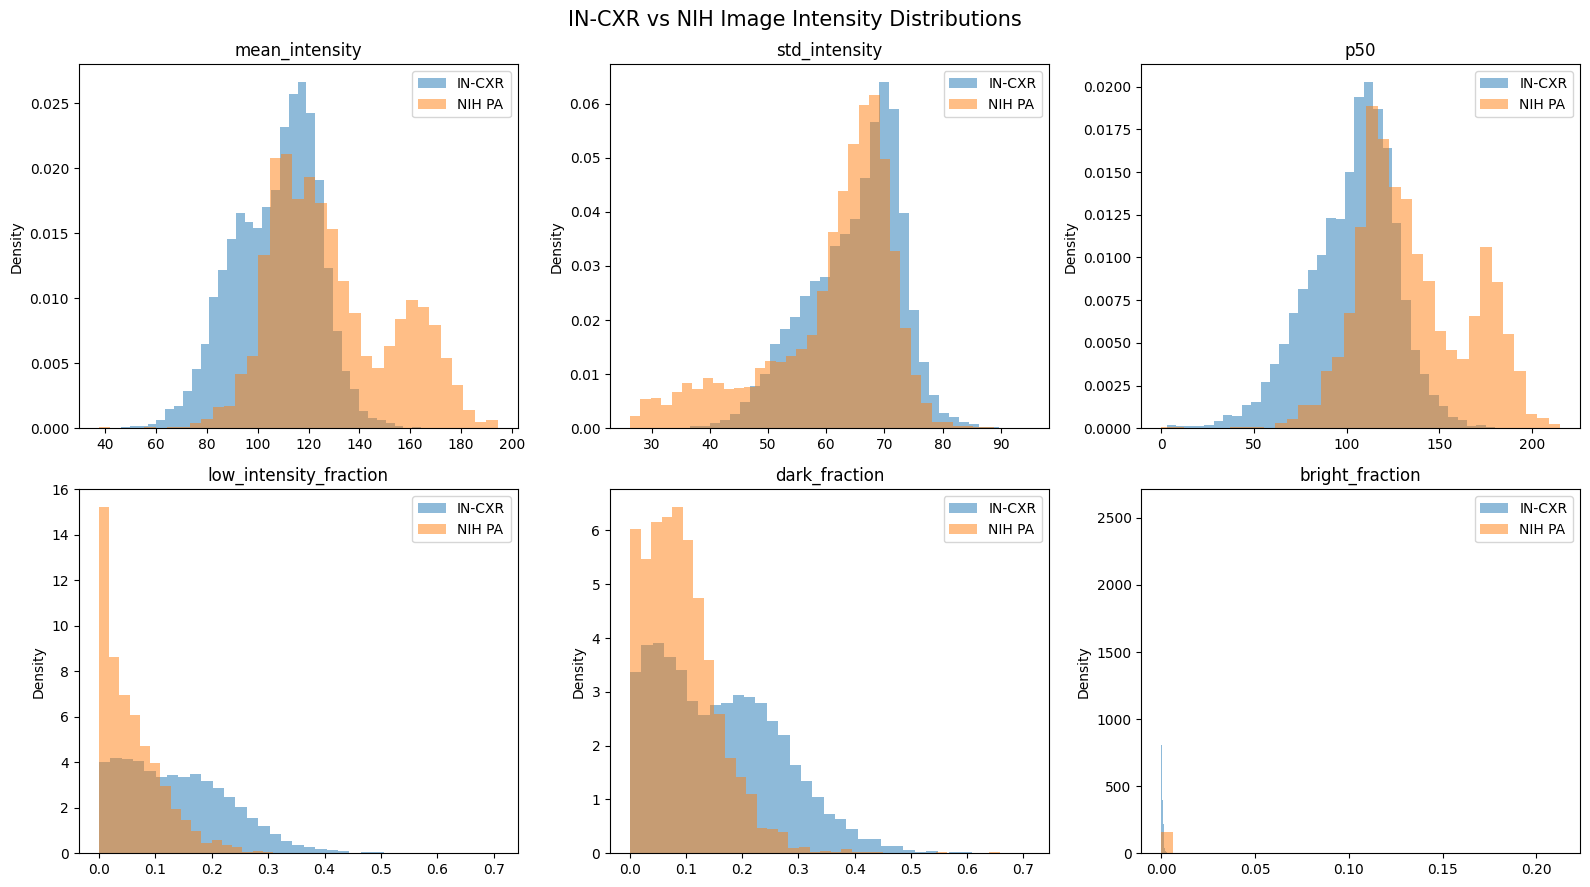

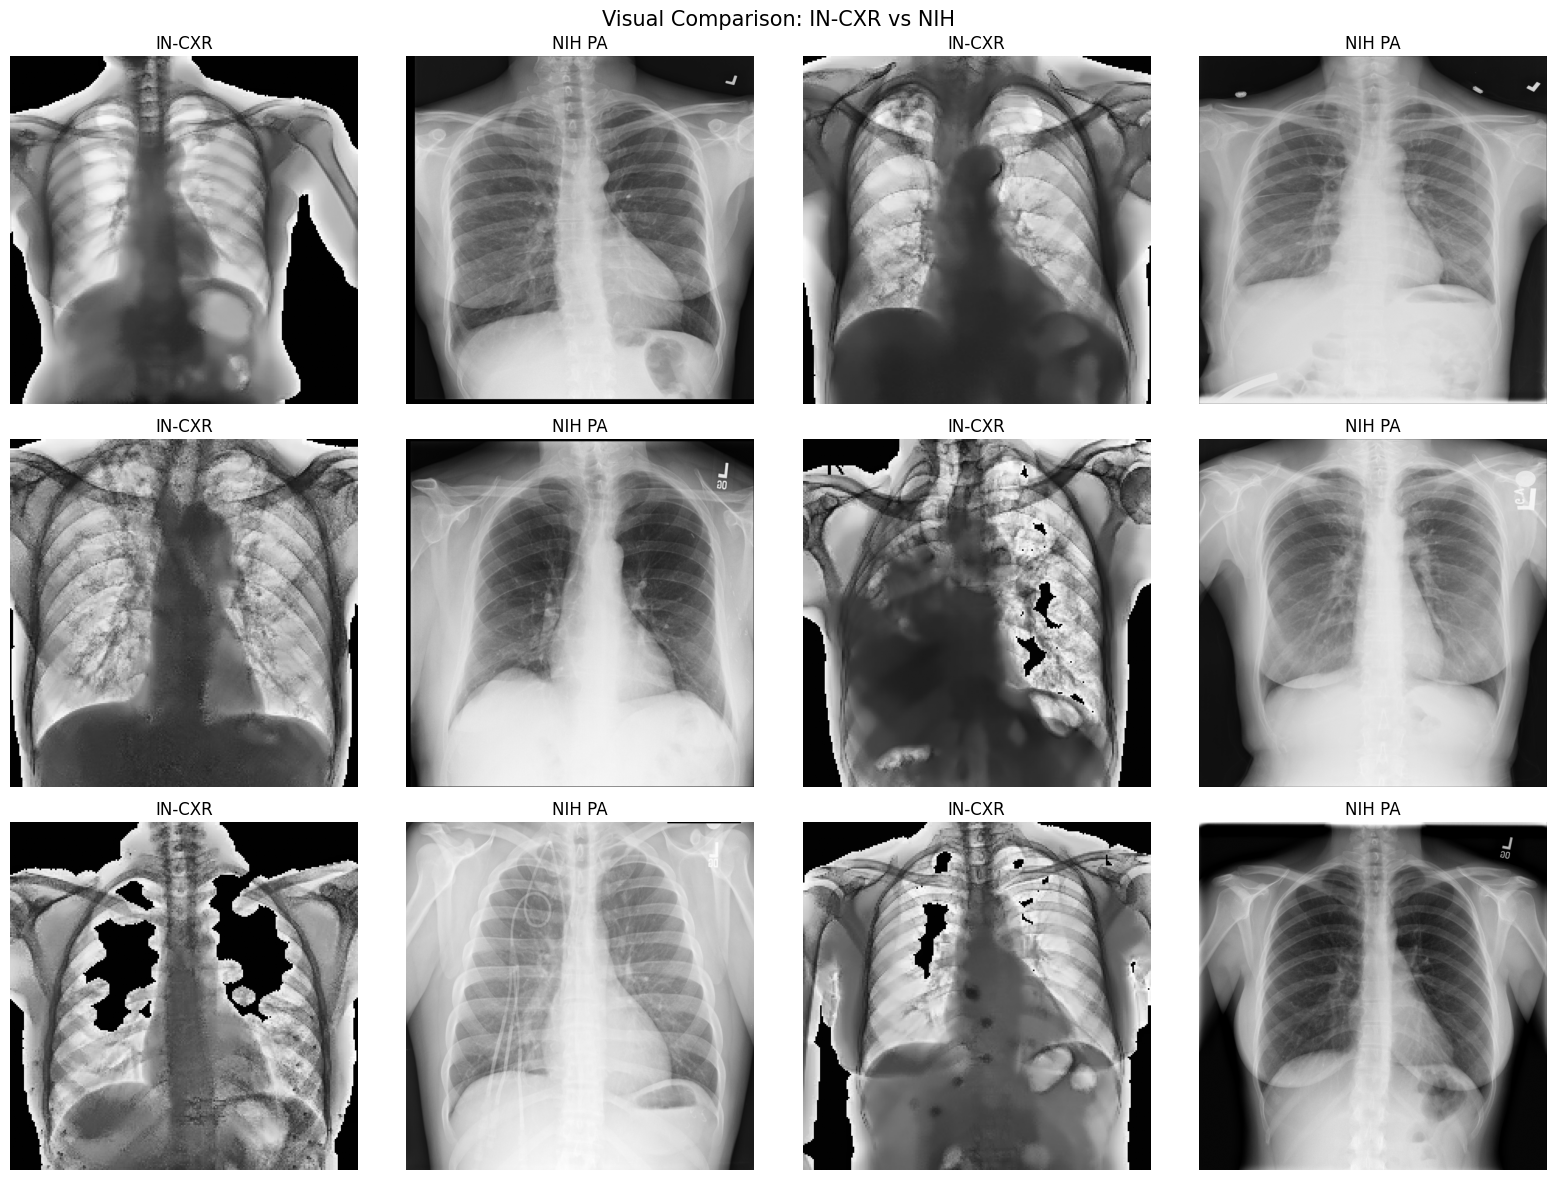


CELL 28.6 COMPLETED
Results: /kaggle/working/lungvision_results/domain_shift_audit


In [4]:
# ============================================================
# CELL 28.6: IN-CXR VS NIH DOMAIN SHIFT AUDIT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

REGISTRY_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/lungvision/"
    "LungVision_AI_Model_Registry"
)

NIH_MANIFEST = Path(
    "/kaggle/working/lungvision_results/"
    "nih_external_validation/nih_pa_evaluation_manifest.csv"
)

INCXR_STATS = (
    REGISTRY_ROOT /
    "experiment_reports/image_quality_audit.csv"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "domain_shift_audit"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for path in [INCXR_STATS, NIH_MANIFEST]:

    if not path.exists():
        raise FileNotFoundError(path)

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

incxr = pd.read_csv(INCXR_STATS)

nih = pd.read_csv(NIH_MANIFEST)

print("=" * 65)
print("LUNGVISION AI | DOMAIN SHIFT AUDIT")
print("=" * 65)

print("\nIN-CXR records:", len(incxr))
print("NIH PA records:", len(nih))

# ------------------------------------------------------------
# 3. EXTRACT IDENTICAL IMAGE STATISTICS
# ------------------------------------------------------------

IMAGE_SIZE = (128, 128)

def extract_features(image_path):

    with Image.open(image_path) as image:

        original_width, original_height = image.size

        image = image.convert("L").resize(
            IMAGE_SIZE,
            Image.Resampling.BILINEAR
        )

        array = np.asarray(
            image,
            dtype=np.float32
        )

    border = np.concatenate([
        array[:12, :].ravel(),
        array[-12:, :].ravel(),
        array[:, :12].ravel(),
        array[:, -12:].ravel()
    ])

    center = array[16:-16, 16:-16]

    return {
        "native_width": original_width,
        "native_height": original_height,
        "native_aspect_ratio": (
            original_width / max(original_height, 1)
        ),
        "mean_intensity": array.mean(),
        "std_intensity": array.std(),
        "p05": np.percentile(array, 5),
        "p25": np.percentile(array, 25),
        "p50": np.percentile(array, 50),
        "p75": np.percentile(array, 75),
        "p95": np.percentile(array, 95),
        "black_fraction": np.mean(array <= 2),
        "low_intensity_fraction": np.mean(array <= 10),
        "dark_fraction": np.mean(array <= 25),
        "bright_fraction": np.mean(array >= 245),
        "border_black_fraction": np.mean(border <= 2),
        "center_black_fraction": np.mean(center <= 2)
    }


# ------------------------------------------------------------
# 4. IN-CXR FEATURE DATA
# ------------------------------------------------------------

incxr_path_col = "resolved_image_path"

if incxr_path_col not in incxr.columns:
    raise ValueError(
        "IN-CXR feature audit does not contain image paths."
    )

incxr_feature_cols = [
    "mean_intensity",
    "std_intensity",
    "p05",
    "p25",
    "p50",
    "p75",
    "p95",
    "black_fraction",
    "low_intensity_fraction",
    "dark_fraction",
    "bright_fraction",
    "border_black_fraction",
    "center_black_fraction"
]

incxr_features = incxr[
    incxr_feature_cols
].copy()

# The original Cell 15 computed these intensity statistics
# after resizing to 128 x 128.
incxr_features = incxr_features.astype(float)

print("\nIN-CXR image features loaded.")

# ------------------------------------------------------------
# 5. NIH FEATURE EXTRACTION
# ------------------------------------------------------------

nih_features = []

for image_path in tqdm(
    nih["resolved_image_path"],
    desc="NIH image analysis"
):

    nih_features.append(
        extract_features(image_path)
    )

nih_features = pd.DataFrame(
    nih_features
)

print("\nNIH feature extraction completed.")

# ------------------------------------------------------------
# 6. DIMENSION COMPARISON
# ------------------------------------------------------------

dimension_summary = pd.DataFrame({
    "IN-CXR": [
        incxr.get("width", pd.Series([np.nan])).mean(),
        incxr.get("height", pd.Series([np.nan])).mean(),
        incxr.get("aspect_ratio", pd.Series([np.nan])).mean()
    ],

    "NIH": [
        nih_features["native_width"].mean(),
        nih_features["native_height"].mean(),
        nih_features["native_aspect_ratio"].mean()
    ]
}, index=[
    "Mean native width",
    "Mean native height",
    "Mean native aspect ratio"
])

print("\nDIMENSION COMPARISON")

display(dimension_summary.round(3))

# Non-square NIH images
non_square_rate = (
    nih_features["native_width"]
    != nih_features["native_height"]
).mean()

print(
    "\nNIH non-square image percentage:",
    round(non_square_rate * 100, 2),
    "%"
)

# ------------------------------------------------------------
# 7. INTENSITY DISTRIBUTION COMPARISON
# ------------------------------------------------------------

summary = []

for feature in incxr_feature_cols:

    summary.append({
        "feature": feature,
        "IN-CXR mean": incxr_features[feature].mean(),
        "NIH mean": nih_features[feature].mean(),
        "IN-CXR std": incxr_features[feature].std(),
        "NIH std": nih_features[feature].std()
    })

summary_df = pd.DataFrame(summary)

print("\nPIXEL DISTRIBUTION COMPARISON")

display(summary_df.round(4))

# ------------------------------------------------------------
# 8. HISTOGRAM COMPARISON
# ------------------------------------------------------------

plot_features = [
    "mean_intensity",
    "std_intensity",
    "p50",
    "low_intensity_fraction",
    "dark_fraction",
    "bright_fraction"
]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 9)
)

axes = axes.flatten()

for ax, feature in zip(
    axes,
    plot_features
):

    ax.hist(
        incxr_features[feature].dropna(),
        bins=35,
        alpha=0.5,
        label="IN-CXR",
        density=True
    )

    ax.hist(
        nih_features[feature].dropna(),
        bins=35,
        alpha=0.5,
        label="NIH PA",
        density=True
    )

    ax.set_title(feature)
    ax.set_ylabel("Density")
    ax.legend()

plt.suptitle(
    "IN-CXR vs NIH Image Intensity Distributions",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. VISUAL SAMPLE COMPARISON
# ------------------------------------------------------------

rng = np.random.default_rng(42)

incxr_samples = incxr.sample(
    n=min(6, len(incxr)),
    random_state=42
)

nih_samples = nih.sample(
    n=min(6, len(nih)),
    random_state=42
)

fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12)
)

for index in range(6):

    row = index // 2
    col = (index % 2) * 2

    # IN-CXR
    incxr_path = incxr_samples.iloc[index][
        "resolved_image_path"
    ]

    with Image.open(incxr_path) as image:

        axes[row, col].imshow(
            image.convert("L"),
            cmap="gray"
        )

    axes[row, col].set_title("IN-CXR")
    axes[row, col].axis("off")

    # NIH
    nih_path = nih_samples.iloc[index][
        "resolved_image_path"
    ]

    with Image.open(nih_path) as image:

        axes[row, col + 1].imshow(
            image.convert("L"),
            cmap="gray"
        )

    axes[row, col + 1].set_title("NIH PA")
    axes[row, col + 1].axis("off")

plt.suptitle(
    "Visual Comparison: IN-CXR vs NIH",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. EXPORT RESULTS
# ------------------------------------------------------------

summary_df.to_csv(
    OUTPUT_DIR / "pixel_distribution_comparison.csv",
    index=False
)

dimension_summary.to_csv(
    OUTPUT_DIR / "dimension_comparison.csv"
)

nih_features.to_csv(
    OUTPUT_DIR / "nih_image_features.csv",
    index=False
)

print("\n" + "=" * 65)
print("CELL 28.6 COMPLETED")
print("=" * 65)

print("Results:", OUTPUT_DIR)

LUNGVISION AI | CONTROLLED PREPROCESSING EXPERIMENT
Device: cuda
GPU: Tesla T4

All required datasets and registry files found.

IN-CXR TRAINING REFERENCE
Training images: 10080
Target mean intensity: 107.269
Target mean standard deviation: 65.005

Building IN-CXR image lookup...
Available IN-CXR training images: 10080

Building reference histogram...


IN-CXR reference:   0%|          | 0/200 [00:00<?, ?it/s]

Reference images: 200
Reference histogram ready.

Preprocessing methods:
- Baseline
- Bicubic
- Lanczos
- CLAHE
- Histogram Matching
- Mean-Std Matching

NIH PA images: 3393
Unique patients: 3025

Both checkpoints verified.

STARTING PREPROCESSING EXPERIMENTS

############################################################
Original ResNet18
############################################################

Preprocessing: Baseline


Baseline:   0%|          | 0/107 [00:00<?, ?it/s]

Threshold 0.5000 | AUC 0.5464 | Sensitivity 0.2639 | Specificity 0.8042
Threshold 0.1765 | AUC 0.5464 | Sensitivity 0.5619 | Specificity 0.4992

Preprocessing: Bicubic


Bicubic:   0%|          | 0/107 [00:00<?, ?it/s]

... (20 outputs left out)

Threshold 0.5000 | AUC 0.5758 | Sensitivity 0.5178 | Specificity 0.5898
Threshold 0.1879 | AUC 0.5758 | Sensitivity 0.7383 | Specificity 0.3417

PREPROCESSING EXPERIMENT RESULTS


,threshold,auc_roc,average_precision,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,brier_score,abnormal_prediction_rate,tn,fp,fn,tp,model,preprocessing
0,0.5000,0.5464,0.4609,0.5803,0.5340,0.4882,0.2639,0.8042,0.3426,0.3102,0.2240,1598,389,1035,371,Original ResNet18,Baseline
1,0.1765,0.5464,0.4609,0.5252,0.5306,0.4426,0.5619,0.4992,0.4951,0.3102,0.5261,992,995,616,790,Original ResNet18,Baseline
2,0.5000,0.5469,0.4611,0.5785,0.5246,0.4805,0.2098,0.8395,0.2921,0.3129,0.1810,1668,319,1111,295,Original ResNet18,Bicubic
3,0.1765,0.5469,0.4611,0.5379,0.5325,0.4485,0.5014,0.5637,0.4735,0.3129,0.4633,1120,867,701,705,Original ResNet18,Bicubic
4,0.5000,0.5461,0.4605,0.5797,0.5204,0.4804,0.1743,0.8666,0.2557,0.3159,0.1503,1722,265,1161,245,Original ResNet18,Lanczos
5,0.1765,0.5461,0.4605,0.5476,0.5364,0.4556,0.4708,0.6019,0.4631,0.3159,0.4282,1196,791,744,662,Original ResNet18,Lanczos
6,0.5000,0.6149,0.5303,0.5927,0.5805,0.5085,0.5092,0.6517,0.5089,0.2915,0.4150,1295,692,690,716,Original ResNet18,CLAHE
7,0.1765,0.6149,0.5303,0.5332,0.5676,0.4620,0.7688,0.3664,0.5771,0.2915,0.6897,728,1259,325,1081,Original ResNet18,CLAHE
8,0.5000,0.5825,0.4946,0.6006,0.5386,0.5573,0.1764,0.9009,0.2680,0.3086,0.1312,1790,197,1158,248,Original ResNet18,Histogram Matching
9,0.1765,0.5825,0.4946,0.5750,0.5542,0.4856,0.4324,0.6759,0.4575,0.3086,0.3690,1343,644,798,608,Original ResNet18,Histogram Matching



AUC IMPROVEMENT OVER BASELINE


,model,preprocessing,auc_roc,auc_change_from_baseline,sensitivity,specificity,accuracy
0,Original ResNet18,Baseline,0.5464,0.0000,0.2639,0.8042,0.5803
2,Original ResNet18,Bicubic,0.5469,0.0004,0.2098,0.8395,0.5785
4,Original ResNet18,Lanczos,0.5461,-0.0004,0.1743,0.8666,0.5797
6,Original ResNet18,CLAHE,0.6149,0.0684,0.5092,0.6517,0.5927
8,Original ResNet18,Histogram Matching,0.5825,0.0360,0.1764,0.9009,0.6006
10,Original ResNet18,Mean-Std Matching,0.5636,0.0172,0.2020,0.8717,0.5942
12,Blur-Augmented ResNet18,Baseline,0.5567,0.0000,0.5619,0.5264,0.5411
14,Blur-Augmented ResNet18,Bicubic,0.5567,-0.0000,0.5413,0.5476,0.5449
16,Blur-Augmented ResNet18,Lanczos,0.5552,-0.0015,0.5213,0.5637,0.5461
18,Blur-Augmented ResNet18,CLAHE,0.6104,0.0537,0.7482,0.3800,0.5326


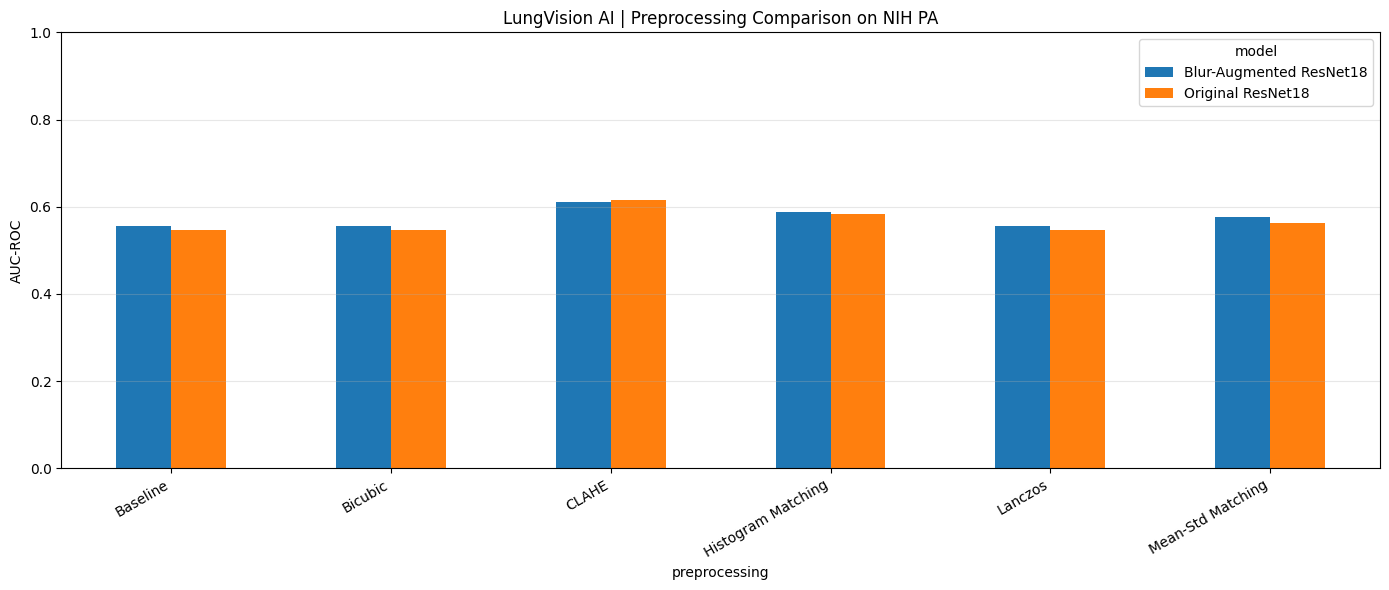


CELL 28.7 COMPLETED
Preprocessing methods: 6
Models: 2
Evaluation images: 3393

Saved files:
/kaggle/working/lungvision_results/preprocessing_experiments/preprocessing_comparison.csv
/kaggle/working/lungvision_results/preprocessing_experiments/preprocessing_auc_comparison.png
/kaggle/working/lungvision_results/preprocessing_experiments/preprocessing_predictions.csv


In [5]:
# ============================================================
# CELL 28.7: CONTROLLED PREPROCESSING EXPERIMENT
# IN-CXR vs NIH DOMAIN ADAPTATION
# ============================================================

import gc
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm

from torchvision import models
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

REGISTRY_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/lungvision/"
    "LungVision_AI_Model_Registry"
)

INCXR_ROOT = Path(
    "/kaggle/input/datasets/arjav007/in-cxr-dataset-png"
)

NIH_ROOT = Path(
    "/kaggle/input/datasets/nih-chest-xrays"
)

NIH_MANIFEST = Path(
    "/kaggle/working/lungvision_results/"
    "nih_external_validation/nih_pa_evaluation_manifest.csv"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "preprocessing_experiments"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

LOCKED_THRESHOLDS = {
    "Original ResNet18": 0.1765,
    "Blur-Augmented ResNet18": 0.1879
}

torch.manual_seed(SEED)
np.random.seed(SEED)

print("=" * 70)
print("LUNGVISION AI | CONTROLLED PREPROCESSING EXPERIMENT")
print("=" * 70)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. VERIFY INPUT FILES
# ------------------------------------------------------------

required_paths = [
    REGISTRY_ROOT,
    INCXR_ROOT,
    NIH_ROOT,
    NIH_MANIFEST
]

for path in required_paths:

    if not path.exists():
        raise FileNotFoundError(
            f"Required input missing: {path}"
        )

print("\nAll required datasets and registry files found.")


# ------------------------------------------------------------
# 3. LOAD IN-CXR TRAINING IMAGE STATISTICS
# ------------------------------------------------------------

INCXR_AUDIT = (
    REGISTRY_ROOT /
    "experiment_reports/image_quality_audit.csv"
)

incxr_audit = pd.read_csv(INCXR_AUDIT)

incxr_train = incxr_audit[
    incxr_audit["split"].astype(str).str.lower() == "train"
].copy()

if incxr_train.empty:
    raise ValueError(
        "No IN-CXR training statistics found."
    )

TARGET_MEAN = float(
    incxr_train["mean_intensity"].mean()
)

TARGET_STD = float(
    incxr_train["std_intensity"].mean()
)

print("\nIN-CXR TRAINING REFERENCE")

print("Training images:", len(incxr_train))
print("Target mean intensity:", round(TARGET_MEAN, 3))
print("Target mean standard deviation:", round(TARGET_STD, 3))


# ------------------------------------------------------------
# 4. BUILD IN-CXR IMAGE LOOKUP
# ------------------------------------------------------------

print("\nBuilding IN-CXR image lookup...")

incxr_lookup = {}

for path in INCXR_ROOT.rglob("*"):

    if path.is_file() and path.suffix.lower() in {
        ".png", ".jpg", ".jpeg"
    }:

        incxr_lookup.setdefault(
            path.name.lower(),
            path
        )

incxr_train["current_path"] = (
    incxr_train["resolved_image_path"]
    .apply(
        lambda p: incxr_lookup.get(
            Path(str(p)).name.lower()
        )
    )
)

incxr_train_available = incxr_train.dropna(
    subset=["current_path"]
).copy()

print(
    "Available IN-CXR training images:",
    len(incxr_train_available)
)

if len(incxr_train_available) < 20:
    raise RuntimeError(
        "Not enough IN-CXR training images available."
    )


# ------------------------------------------------------------
# 5. BUILD REFERENCE HISTOGRAM
# ------------------------------------------------------------

# Use only IN-CXR training images.
# Never use validation/test images to build this reference.

REFERENCE_COUNT = min(
    200,
    len(incxr_train_available)
)

reference_samples = incxr_train_available.sample(
    n=REFERENCE_COUNT,
    random_state=SEED
)

reference_histogram = np.zeros(
    256,
    dtype=np.int64
)

print("\nBuilding reference histogram...")

for path in tqdm(
    reference_samples["current_path"],
    desc="IN-CXR reference"
):

    with Image.open(path) as image:

        image = image.convert("L").resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.BILINEAR
        )

        pixels = np.asarray(
            image,
            dtype=np.uint8
        )

    reference_histogram += np.bincount(
        pixels.ravel(),
        minlength=256
    )

reference_cdf = (
    np.cumsum(reference_histogram).astype(np.float64)
    / reference_histogram.sum()
)

reference_values = np.arange(
    256,
    dtype=np.float64
)

print("Reference images:", REFERENCE_COUNT)
print("Reference histogram ready.")


# ------------------------------------------------------------
# 6. DEFINE PREPROCESSING METHODS
# ------------------------------------------------------------

def baseline_transform(array):

    image = Image.fromarray(array)

    return image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BILINEAR
    )


def bicubic_transform(array):

    image = Image.fromarray(array)

    return image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BICUBIC
    )


def lanczos_transform(array):

    image = Image.fromarray(array)

    return image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.LANCZOS
    )


def clahe_transform(array):

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(
        array.astype(np.uint8)
    )

    return baseline_transform(enhanced)


def histogram_matching_transform(array):

    source_histogram = np.bincount(
        array.ravel(),
        minlength=256
    )

    source_cdf = (
        np.cumsum(source_histogram).astype(np.float64)
        / source_histogram.sum()
    )

    mapping = np.interp(
        source_cdf,
        reference_cdf,
        reference_values
    )

    matched = np.clip(
        mapping[array],
        0,
        255
    ).astype(np.uint8)

    return baseline_transform(matched)


def mean_std_matching_transform(array):

    array_float = array.astype(np.float32)

    source_mean = array_float.mean()
    source_std = array_float.std()

    normalized = (
        array_float - source_mean
    ) / max(source_std, 1e-6)

    matched = (
        normalized * TARGET_STD + TARGET_MEAN
    )

    matched = np.clip(
        matched,
        0,
        255
    ).astype(np.uint8)

    return baseline_transform(matched)


PREPROCESSING_METHODS = {
    "Baseline": baseline_transform,
    "Bicubic": bicubic_transform,
    "Lanczos": lanczos_transform,
    "CLAHE": clahe_transform,
    "Histogram Matching": histogram_matching_transform,
    "Mean-Std Matching": mean_std_matching_transform
}

print("\nPreprocessing methods:")

for name in PREPROCESSING_METHODS:
    print("-", name)


# ------------------------------------------------------------
# 7. LOAD NIH PA MANIFEST
# ------------------------------------------------------------

nih_df = pd.read_csv(
    NIH_MANIFEST
)

required_columns = [
    "resolved_image_path",
    "external_label",
    "Patient ID"
]

missing_columns = [
    col for col in required_columns
    if col not in nih_df.columns
]

if missing_columns:
    raise ValueError(
        f"NIH manifest missing columns: {missing_columns}"
    )

nih_df = nih_df.reset_index(drop=True)

y_true = nih_df[
    "external_label"
].to_numpy().astype(int)

print("\nNIH PA images:", len(nih_df))
print("Unique patients:", nih_df["Patient ID"].nunique())


# ------------------------------------------------------------
# 8. CREATE PREPROCESSING DATASET
# ------------------------------------------------------------

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class NIHPreprocessingDataset(Dataset):

    def __init__(self, dataframe, transform_function):

        self.data = dataframe.reset_index(drop=True)
        self.transform_function = transform_function

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        with Image.open(
            row["resolved_image_path"]
        ) as image:

            image = image.convert("L")

            array = np.asarray(
                image,
                dtype=np.uint8
            )

        processed = self.transform_function(
            array
        )

        # Reproduce original grayscale-to-RGB procedure
        rgb = processed.convert("RGB")

        tensor = TF.to_tensor(rgb)

        tensor = TF.normalize(
            tensor,
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD
        )

        return (
            tensor,
            int(row["external_label"])
        )


# ------------------------------------------------------------
# 9. LOAD BOTH CHECKPOINTS
# ------------------------------------------------------------

original_path = (
    REGISTRY_ROOT /
    "models/original_resnet18/model.pth"
)

augmented_path = (
    REGISTRY_ROOT /
    "models/blur_augmented_resnet18/model.pth"
)


def load_model(checkpoint_path):

    if not checkpoint_path.exists():
        raise FileNotFoundError(checkpoint_path)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    network = models.resnet18(
        weights=None
    )

    network.fc = nn.Linear(
        network.fc.in_features,
        1
    )

    network.load_state_dict(
        checkpoint["model_state_dict"]
    )

    network = network.to(DEVICE)
    network.eval()

    return network


models_to_evaluate = {
    "Original ResNet18": original_path,
    "Blur-Augmented ResNet18": augmented_path
}

print("\nBoth checkpoints verified.")


# ------------------------------------------------------------
# 10. METRIC FUNCTION
# ------------------------------------------------------------

def calculate_metrics(
    y_true,
    y_prob,
    threshold
):

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "threshold": threshold,

        "auc_roc": roc_auc_score(
            y_true,
            y_prob
        ),

        "average_precision": average_precision_score(
            y_true,
            y_prob
        ),

        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "sensitivity": (
            tp / (tp + fn)
            if tp + fn else 0
        ),

        "specificity": (
            tn / (tn + fp)
            if tn + fp else 0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "brier_score": brier_score_loss(
            y_true,
            y_prob
        ),

        "abnormal_prediction_rate": y_pred.mean(),

        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }


# ------------------------------------------------------------
# 11. RUN CONTROLLED EVALUATION
# ------------------------------------------------------------

all_metrics = []
probability_results = {}

print("\n" + "=" * 70)
print("STARTING PREPROCESSING EXPERIMENTS")
print("=" * 70)

for model_name, checkpoint_path in models_to_evaluate.items():

    print("\n" + "#" * 60)
    print(model_name)
    print("#" * 60)

    network = load_model(checkpoint_path)

    for transform_name, transform_function in PREPROCESSING_METHODS.items():

        print("\nPreprocessing:", transform_name)

        dataset = NIHPreprocessingDataset(
            nih_df,
            transform_function
        )

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available()
        )

        probabilities = []

        with torch.inference_mode():

            for images, labels in tqdm(
                loader,
                desc=transform_name,
                leave=False
            ):

                images = images.to(
                    DEVICE,
                    non_blocking=True
                )

                logits = network(images).flatten()

                probs = torch.sigmoid(logits)

                probabilities.extend(
                    probs.cpu().numpy()
                )

        probabilities = np.asarray(
            probabilities,
            dtype=float
        )

        if len(probabilities) != len(nih_df):
            raise ValueError(
                "Prediction count mismatch."
            )

        y_key = (
            model_name + "_" + transform_name
        )

        probability_results[y_key] = probabilities

        thresholds = [
            0.50,
            LOCKED_THRESHOLDS[model_name]
        ]

        for threshold in thresholds:

            metrics = calculate_metrics(
                y_true,
                probabilities,
                threshold
            )

            metrics["model"] = model_name
            metrics["preprocessing"] = transform_name

            all_metrics.append(metrics)

            print(
                f"Threshold {threshold:.4f} | "
                f"AUC {metrics['auc_roc']:.4f} | "
                f"Sensitivity {metrics['sensitivity']:.4f} | "
                f"Specificity {metrics['specificity']:.4f}"
            )

        del dataset, loader

        gc.collect()

    del network

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 12. BUILD RESULTS TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(
    all_metrics
)

print("\n" + "=" * 70)
print("PREPROCESSING EXPERIMENT RESULTS")
print("=" * 70)

display(
    results_df.round(4)
)

results_df.to_csv(
    OUTPUT_DIR / "preprocessing_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 13. COMPARE BASELINE AUC WITH ALL METHODS
# ------------------------------------------------------------

auc_df = results_df[
    results_df["threshold"] == 0.50
].copy()

baseline_auc = {}

for model_name in models_to_evaluate:

    baseline_row = auc_df[
        (auc_df["model"] == model_name)
        & (auc_df["preprocessing"] == "Baseline")
    ]

    baseline_auc[model_name] = float(
        baseline_row["auc_roc"].iloc[0]
    )

auc_df["auc_change_from_baseline"] = auc_df.apply(
    lambda row: (
        row["auc_roc"]
        - baseline_auc[row["model"]]
    ),
    axis=1
)

print("\nAUC IMPROVEMENT OVER BASELINE")

display(
    auc_df[
        [
            "model",
            "preprocessing",
            "auc_roc",
            "auc_change_from_baseline",
            "sensitivity",
            "specificity",
            "accuracy"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# 14. PLOT AUC COMPARISON
# ------------------------------------------------------------

auc_pivot = auc_df.pivot(
    index="preprocessing",
    columns="model",
    values="auc_roc"
)

auc_pivot.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title(
    "LungVision AI | Preprocessing Comparison on NIH PA"
)

plt.ylabel("AUC-ROC")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "preprocessing_auc_comparison.png",
    dpi=180
)

plt.show()


# ------------------------------------------------------------
# 15. SAVE PREDICTIONS
# ------------------------------------------------------------

prediction_export = nih_df[
    [
        "Image Index",
        "Patient ID",
        "external_label",
        "Finding Labels"
    ]
].copy()

for key, probabilities in probability_results.items():

    safe_name = key.lower().replace(" ", "_")

    prediction_export[
        safe_name + "_probability"
    ] = probabilities

prediction_export.to_csv(
    OUTPUT_DIR / "preprocessing_predictions.csv",
    index=False
)


# ------------------------------------------------------------
# 16. COMPLETION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 28.7 COMPLETED")
print("=" * 70)

print("Preprocessing methods:", len(PREPROCESSING_METHODS))
print("Models:", len(models_to_evaluate))
print("Evaluation images:", len(nih_df))

print("\nSaved files:")
print(OUTPUT_DIR / "preprocessing_comparison.csv")
print(OUTPUT_DIR / "preprocessing_auc_comparison.png")
print(OUTPUT_DIR / "preprocessing_predictions.csv")

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [6]:
# ============================================================
# CELL 28.8.1: COMPLETE NIH EXPERT-LABEL AUDIT
# ============================================================

import re
import numpy as np
import pandas as pd

from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

EXPERT_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/"
    "lungvision-nih-expert-labels"
)

NIH_ROOT = Path(
    "/kaggle/input/datasets/nih-chest-xrays"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "nih_expert_label_audit"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

GROUND_TRUTH_READERS = {
    "4343882785",
    "4343883593",
    "4343883996"
}

# ------------------------------------------------------------
# 2. LOAD EXPERT LABEL FILES
# ------------------------------------------------------------

labels_candidates = list(
    EXPERT_ROOT.rglob(
        "*all_findings_expert_labels_test_labels.csv"
    )
)

reader_candidates = list(
    EXPERT_ROOT.rglob(
        "*all_findings_expert_labels_test_individual_readers.csv"
    )
)

if not labels_candidates:
    raise FileNotFoundError(
        "Expert ground-truth CSV not found."
    )

if not reader_candidates:
    raise FileNotFoundError(
        "Individual reader CSV not found."
    )

LABEL_PATH = labels_candidates[0]
READER_PATH = reader_candidates[0]

expert = pd.read_csv(
    LABEL_PATH,
    dtype=str
)

readers = pd.read_csv(
    READER_PATH,
    dtype=str
)

print("=" * 70)
print("LUNGVISION AI | NIH EXPERT-LABEL AUDIT")
print("=" * 70)

print("Expert-label file:", LABEL_PATH)
print("Reader file:", READER_PATH)

print("\nExpert shape:", expert.shape)
print("Reader shape:", readers.shape)

# ------------------------------------------------------------
# 3. DETECT COLUMN NAMES
# ------------------------------------------------------------

def normalize_column(name):

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(name).lower()
    )


def find_column(dataframe, aliases):

    lookup = {
        normalize_column(c): c
        for c in dataframe.columns
    }

    for alias in aliases:

        key = normalize_column(alias)

        if key in lookup:
            return lookup[key]

    return None


GT_IMAGE_COL = find_column(
    expert,
    ["Image ID"]
)

GT_PATIENT_COL = find_column(
    expert,
    ["Patient ID"]
)

READER_IMAGE_COL = find_column(
    readers,
    ["Image ID"]
)

READER_PATIENT_COL = find_column(
    readers,
    ["Patient ID"]
)

READER_ID_COL = find_column(
    readers,
    ["Reader ID"]
)

if not all([
    GT_IMAGE_COL,
    GT_PATIENT_COL,
    READER_IMAGE_COL,
    READER_PATIENT_COL,
    READER_ID_COL
]):
    raise ValueError(
        "Required identifiers are missing."
    )

# ------------------------------------------------------------
# 4. NORMALIZE IDENTIFIERS
# ------------------------------------------------------------

def normalize_identifier(value):

    if pd.isna(value):
        return None

    value = str(value).strip()

    if value.endswith(".0"):
        value = value[:-2]

    return value


def normalize_image_id(value):

    if pd.isna(value):
        return None

    return Path(
        str(value).strip()
    ).name.lower()


def image_stem(value):

    if pd.isna(value):
        return None

    return Path(
        str(value).strip()
    ).stem.lower()


expert["image_key"] = expert[
    GT_IMAGE_COL
].apply(normalize_image_id)

readers["image_key"] = readers[
    READER_IMAGE_COL
].apply(normalize_image_id)

expert["patient_key"] = expert[
    GT_PATIENT_COL
].apply(normalize_identifier)

readers["patient_key"] = readers[
    READER_PATIENT_COL
].apply(normalize_identifier)

readers["reader_key"] = readers[
    READER_ID_COL
].apply(normalize_identifier)

# ------------------------------------------------------------
# 5. BASIC DATA INTEGRITY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DATA INTEGRITY")
print("=" * 60)

print("Expert rows:", len(expert))
print("Unique expert images:", expert["image_key"].nunique())

print("Reader rows:", len(readers))
print("Unique reader images:", readers["image_key"].nunique())

print("Unique patients:", expert["patient_key"].nunique())
print("Unique readers:", readers["reader_key"].nunique())

print(
    "Duplicate expert image IDs:",
    expert["image_key"].duplicated().sum()
)

print(
    "Duplicate image-reader pairs:",
    readers.duplicated(
        ["image_key", "reader_key"]
    ).sum()
)

# ------------------------------------------------------------
# 6. VERIFY FIVE READERS PER IMAGE
# ------------------------------------------------------------

reader_counts = (
    readers.groupby("image_key")
    .agg(
        reader_count=("reader_key", "nunique"),
        reader_rows=("reader_key", "size"),
        patient_count=("patient_key", "nunique")
    )
)

print("\nREADER COMPLETENESS")

print(
    reader_counts["reader_count"]
    .value_counts()
    .sort_index()
)

five_reader_images = int(
    (reader_counts["reader_count"] == 5).sum()
)

print(
    "Images with exactly five readers:",
    five_reader_images
)

# ------------------------------------------------------------
# 7. VERIFY PATIENT IDENTIFIERS
# ------------------------------------------------------------

reader_patient_map = (
    readers.groupby("image_key", as_index=False)
    .agg(
        reader_patient_id=("patient_key", "first"),
        reader_patient_count=("patient_key", "nunique")
    )
)

patient_check = expert[
    ["image_key", "patient_key"]
].merge(
    reader_patient_map,
    on="image_key",
    how="left",
    validate="one_to_one"
)

patient_check["patient_match"] = (
    patient_check["patient_key"]
    == patient_check["reader_patient_id"]
)

patient_mismatches = int(
    (~patient_check["patient_match"]).sum()
)

inconsistent_reader_patients = int(
    (patient_check["reader_patient_count"] != 1).sum()
)

print("\nPATIENT IDENTIFIER VERIFICATION")

print("Expert images:", len(patient_check))
print("Patient mismatches:", patient_mismatches)

print(
    "Images with inconsistent reader patient IDs:",
    inconsistent_reader_patients
)

# ------------------------------------------------------------
# 8. VERIFY THREE DESIGNATED GROUND-TRUTH READERS
# ------------------------------------------------------------

available_readers = set(
    readers["reader_key"].dropna().unique()
)

missing_readers = (
    GROUND_TRUTH_READERS - available_readers
)

if missing_readers:
    raise ValueError(
        f"Required ground-truth readers missing: {missing_readers}"
    )

gt_reader_rows = readers[
    readers["reader_key"].isin(
        GROUND_TRUTH_READERS
    )
].copy()

gt_counts = (
    gt_reader_rows.groupby("image_key")["reader_key"]
    .nunique()
)

print("\nGROUND-TRUTH READER VERIFICATION")

print("Designated readers:", GROUND_TRUTH_READERS)
print("Selected reader records:", len(gt_reader_rows))
print("Unique images:", gt_counts.size)

print(
    "Images with exactly three designated readers:",
    int((gt_counts == 3).sum())
)

if (
    not (gt_counts == 3).all()
    or len(gt_counts) != len(expert)
):
    raise ValueError(
        "Ground-truth reader completeness failed."
    )

# ------------------------------------------------------------
# 9. IDENTIFY ALL SHARED LABEL COLUMNS
# ------------------------------------------------------------

id_columns = {
    GT_IMAGE_COL,
    GT_PATIENT_COL,
    "image_key",
    "patient_key"
}

reader_id_columns = {
    READER_IMAGE_COL,
    READER_PATIENT_COL,
    READER_ID_COL,
    "image_key",
    "patient_key",
    "reader_key"
}

gt_label_cols = [
    c for c in expert.columns
    if c not in id_columns
]

reader_label_cols = [
    c for c in readers.columns
    if c not in reader_id_columns
]

reader_column_map = {
    normalize_column(c): c
    for c in reader_label_cols
}

shared_pairs = []

for col in gt_label_cols:

    key = normalize_column(col)

    if key in reader_column_map:

        shared_pairs.append(
            (col, reader_column_map[key])
        )

print("\nMATCHING LABEL COLUMNS")

print("Shared columns:", len(shared_pairs))

for gt_col, reader_col in shared_pairs:
    print(gt_col)

if not shared_pairs:
    raise ValueError(
        "No matching reader-label columns."
    )

# ------------------------------------------------------------
# 10. ROBUST LABEL CONVERSION
# ------------------------------------------------------------

def to_binary(series):

    values = (
        series.astype("string")
        .str.strip()
        .str.upper()
    )

    mapping = {
        "YES": 1,
        "Y": 1,
        "1": 1,
        "1.0": 1,
        "TRUE": 1,
        "PRESENT": 1,
        "ABNORMAL": 1,

        "NO": 0,
        "N": 0,
        "0": 0,
        "0.0": 0,
        "FALSE": 0,
        "ABSENT": 0,
        "NORMAL": 0
    }

    return values.map(mapping)


# ------------------------------------------------------------
# 11. RECOMPUTE THREE-READER MAJORITY VOTES
# ------------------------------------------------------------

vote_data = gt_reader_rows[
    ["image_key"]
].copy()

label_names = []

for gt_col, reader_col in shared_pairs:

    label_names.append(gt_col)

    vote_data[gt_col] = to_binary(
        gt_reader_rows[reader_col]
    ).values

# Sum votes, requiring all three reader values to be valid
vote_counts = (
    vote_data.groupby("image_key")[label_names]
    .sum(min_count=3)
)

# Majority means at least 2 of the 3 selected readers
majority_votes = (
    vote_counts.ge(2)
    .astype(float)
)

majority_votes = majority_votes.where(
    vote_counts.notna()
)

majority_votes = majority_votes.reset_index()

print("\nMAJORITY VOTE RECONSTRUCTION")

print("Images:", len(majority_votes))

# ------------------------------------------------------------
# 12. MERGE WITH OFFICIAL GROUND TRUTH
# ------------------------------------------------------------

comparison = expert.merge(
    majority_votes,
    on="image_key",
    how="inner",
    suffixes=("_official", "_recomputed"),
    validate="one_to_one"
)

print(
    "Official/recomputed matched images:",
    len(comparison)
)

# ------------------------------------------------------------
# 13. VERIFY NORMAL / ABNORMAL + FINDING VOTES
# ------------------------------------------------------------

agreement_results = []

for col in label_names:

    # The Other label has a separate rule.
    if normalize_column(col) == "other":
        continue

    official = to_binary(
        comparison[f"{col}_official"]
    )

    recomputed = pd.to_numeric(
        comparison[f"{col}_recomputed"],
        errors="coerce"
    )

    valid = (
        official.notna()
        & recomputed.notna()
    )

    agreement = (
        official[valid].to_numpy()
        == recomputed[valid].to_numpy()
    )

    agreement_results.append({
        "label": col,
        "images_compared": int(valid.sum()),
        "agreement": (
            float(agreement.mean())
            if valid.any()
            else np.nan
        ),
        "mismatches": int((~agreement).sum())
    })

agreement_df = pd.DataFrame(
    agreement_results
)

print("\nOFFICIAL VS RECOMPUTED MAJORITY VOTE")

display(
    agreement_df.round(4)
)

# ------------------------------------------------------------
# 14. VERIFY SPECIAL OTHER LABEL RULE
# ------------------------------------------------------------

# According to the README:
# Other = YES if:
# A. At least 2 readers selected Other,
# OR
# B. At least 2 readers selected Abnormal AND
#    no individual finding received 2 YES votes.

abnormal_col = next(
    c for c in label_names
    if normalize_column(c) == "abnormal"
)

other_col = next(
    c for c in label_names
    if normalize_column(c) == "other"
)

finding_cols = [
    c for c in label_names
    if normalize_column(c) not in [
        "abnormal",
        "other"
    ]
]

majority_abnormal = (
    vote_counts[abnormal_col] >= 2
)

majority_other = (
    vote_counts[other_col] >= 2
)

any_majority_finding = (
    vote_counts[finding_cols] >= 2
).any(axis=1)

special_other = (
    majority_other
    | (
        majority_abnormal
        & ~any_majority_finding
    )
)

special_other = special_other.astype(float)

special_other.name = "special_other_recomputed"

other_comparison = expert[
    ["image_key", other_col]
].merge(
    special_other.reset_index(),
    on="image_key",
    how="inner",
    validate="one_to_one"
)

official_other = to_binary(
    other_comparison[other_col]
)

recomputed_other = other_comparison[
    "special_other_recomputed"
]

valid_other = (
    official_other.notna()
    & recomputed_other.notna()
)

other_agreement = (
    official_other[valid_other].to_numpy()
    == recomputed_other[valid_other].to_numpy()
)

print("\nSPECIAL OTHER LABEL VERIFICATION")

print(
    "Images compared:",
    int(valid_other.sum())
)

print(
    "Agreement:",
    round(float(other_agreement.mean()), 4)
    if valid_other.any()
    else np.nan
)

print(
    "Mismatches:",
    int((~other_agreement).sum())
)

agreement_df = pd.concat(
    [
        agreement_df,
        pd.DataFrame([{
            "label": "Other (special rule)",
            "images_compared": int(valid_other.sum()),
            "agreement": (
                float(other_agreement.mean())
                if valid_other.any()
                else np.nan
            ),
            "mismatches": int((~other_agreement).sum())
        }])
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# 15. NORMAL / ABNORMAL DISTRIBUTION
# ------------------------------------------------------------

expert["abnormal_binary"] = to_binary(
    expert[abnormal_col]
)

print("\nEXPERT NORMAL / ABNORMAL DISTRIBUTION")

print("YES = Abnormal")
print("NO = Normal")

print(
    expert["abnormal_binary"]
    .value_counts(dropna=False)
    .rename({
        0: "Normal",
        1: "Abnormal"
    })
)

# ------------------------------------------------------------
# 16. OVERLAP WITH EXISTING NIH SAMPLE
# ------------------------------------------------------------

sample_csv = next(
    NIH_ROOT.rglob("sample_labels.csv"),
    None
)

if sample_csv is None:
    raise FileNotFoundError(
        "NIH sample_labels.csv not found."
    )

sample_df = pd.read_csv(
    sample_csv,
    dtype=str
)

expert["image_stem"] = expert[
    GT_IMAGE_COL
].apply(image_stem)

sample_df["image_stem"] = sample_df[
    "Image Index"
].apply(image_stem)

expert_subset = expert[
    [
        "image_key",
        "image_stem",
        "patient_key",
        "abnormal_binary"
    ]
].rename(
    columns={
        "patient_key": "expert_patient_id",
        "abnormal_binary": "expert_abnormal_label"
    }
)

sample_subset = sample_df[
    [
        "image_stem",
        "Patient ID",
        "View Position",
        "Finding Labels"
    ]
].copy()

sample_subset = sample_subset.rename(
    columns={
        "Patient ID": "sample_patient_id",
        "View Position": "sample_view_position",
        "Finding Labels": "sample_finding_labels"
    }
)

overlap = expert_subset.merge(
    sample_subset,
    on="image_stem",
    how="inner",
    validate="one_to_one"
)

overlap["patient_match"] = (
    overlap["expert_patient_id"]
    == overlap["sample_patient_id"].apply(
        normalize_identifier
    )
)

print("\nNIH SAMPLE OVERLAP")

print("Expert images:", len(expert))
print("Matched images:", len(overlap))

print(
    "Overlapping patients:",
    overlap["expert_patient_id"].nunique()
)

print(
    "Patient ID mismatches:",
    int((~overlap["patient_match"]).sum())
)

if len(overlap):

    print("\nOverlap view positions:")

    display(
        overlap["sample_view_position"].value_counts()
    )

# ------------------------------------------------------------
# 17. CHECK ALL EXPERT IMAGES IN AVAILABLE NIH SAMPLE
# ------------------------------------------------------------

image_lookup = {}

for path in NIH_ROOT.rglob("*"):

    if path.is_file() and path.suffix.lower() in {
        ".png", ".jpg", ".jpeg"
    }:

        image_lookup.setdefault(
            path.name.lower(),
            path
        )

        image_lookup.setdefault(
            path.stem.lower(),
            path
        )


def locate_image(value):

    if pd.isna(value):
        return None

    filename = Path(
        str(value)
    ).name.lower()

    stem = Path(
        str(value)
    ).stem.lower()

    return image_lookup.get(
        filename,
        image_lookup.get(stem)
    )


expert["resolved_image_path"] = expert[
    GT_IMAGE_COL
].apply(locate_image)

available = expert.dropna(
    subset=["resolved_image_path"]
).copy()

missing = expert[
    expert["resolved_image_path"].isna()
].copy()

print("\nEXPERT IMAGE AVAILABILITY")

print("Available:", len(available))
print("Missing:", len(missing))

# ------------------------------------------------------------
# 18. SAVE AUDIT RESULTS
# ------------------------------------------------------------

expert.to_csv(
    OUTPUT_DIR / "expert_ground_truth_audit.csv",
    index=False
)

readers.to_csv(
    OUTPUT_DIR / "expert_individual_readers.csv",
    index=False
)

patient_check.to_csv(
    OUTPUT_DIR / "patient_mapping_check.csv",
    index=False
)

reader_counts.to_csv(
    OUTPUT_DIR / "reader_counts_per_image.csv"
)

agreement_df.to_csv(
    OUTPUT_DIR / "majority_vote_verification.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / "official_vs_recomputed_votes.csv",
    index=False
)

overlap.to_csv(
    OUTPUT_DIR / "expert_nih_sample_overlap.csv",
    index=False
)

available.to_csv(
    OUTPUT_DIR / "expert_images_available.csv",
    index=False
)

missing.to_csv(
    OUTPUT_DIR / "expert_images_missing.csv",
    index=False
)

# ------------------------------------------------------------
# 19. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NIH EXPERT-LABEL AUDIT COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Ground-truth images:", len(expert))
print("Individual reader records:", len(readers))
print("Unique radiologists:", readers["reader_key"].nunique())

print("Five-reader images:", five_reader_images)
print("Three-reader GT images:", int((gt_counts == 3).sum()))

print("Patient mismatches:", patient_mismatches)

print("Majority-vote label checks:", len(agreement_df))
print("Existing NIH sample overlap:", len(overlap))

print("Expert images available:", len(available))
print("Expert images missing:", len(missing))

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nCELL 28.8.1 COMPLETED")

LUNGVISION AI | NIH EXPERT-LABEL AUDIT
Expert-label file: /kaggle/input/datasets/babulkumar07/lungvision-nih-expert-labels/nih-cxr-14_labels_all_findings_expert_labels_test_labels.csv
Reader file: /kaggle/input/datasets/babulkumar07/lungvision-nih-expert-labels/nih-cxr-14_labels_all_findings_expert_labels_test_individual_readers.csv

Expert shape: (810, 18)
Reader shape: (4050, 19)

DATA INTEGRITY
Expert rows: 810
Unique expert images: 810
Reader rows: 4050
Unique reader images: 810
Unique patients: 532
Unique readers: 5
Duplicate expert image IDs: 0
Duplicate image-reader pairs: 0

READER COMPLETENESS
reader_count
5    810
Name: count, dtype: int64
Images with exactly five readers: 810

PATIENT IDENTIFIER VERIFICATION
Expert images: 810
Patient mismatches: 0
Images with inconsistent reader patient IDs: 0

GROUND-TRUTH READER VERIFICATION
Designated readers: {'4343883996', '4343883593', '4343882785'}
Selected reader records: 2430
Unique images: 810
Images with exactly three designated 

,label,images_compared,agreement,mismatches
0,Abnormal,810,1.0,0
1,Atelectasis,810,1.0,0
2,Cardiomegaly,810,1.0,0
3,Effusion,810,1.0,0
4,Infiltration,810,1.0,0
5,Mass,810,1.0,0
6,Nodule,810,1.0,0
7,Pneumonia,810,1.0,0
8,Pneumothorax,810,1.0,0
9,Consolidation,810,1.0,0



SPECIAL OTHER LABEL VERIFICATION
Images compared: 810
Agreement: 1.0
Mismatches: 0

EXPERT NORMAL / ABNORMAL DISTRIBUTION
YES = Abnormal
NO = Normal
abnormal_binary
Abnormal    578
Normal      232
Name: count, dtype: int64

NIH SAMPLE OVERLAP
Expert images: 810
Matched images: 27
Overlapping patients: 27
Patient ID mismatches: 27

Overlap view positions:


sample_view_position
PA    27
Name: count, dtype: int64


EXPERT IMAGE AVAILABILITY
Available: 27
Missing: 783

NIH EXPERT-LABEL AUDIT COMPLETED SUCCESSFULLY
Ground-truth images: 810
Individual reader records: 4050
Unique radiologists: 5
Five-reader images: 810
Three-reader GT images: 810
Patient mismatches: 0
Majority-vote label checks: 16
Existing NIH sample overlap: 27
Expert images available: 27
Expert images missing: 783

Output directory:
/kaggle/working/lungvision_results/nih_expert_label_audit

CELL 28.8.1 COMPLETED


In [7]:
# ============================================================
# CELL 28.9: NIH EXPERT IMAGE RECOVERY FROM GCS
# ============================================================

import requests
import pandas as pd
import numpy as np

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from PIL import Image
from io import BytesIO

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

EXPERT_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/"
    "lungvision-nih-expert-labels"
)

NIH_ROOT = Path(
    "/kaggle/input/datasets/nih-chest-xrays"
)

GCS_PREFIX = (
    "https://storage.googleapis.com/"
    "healthai-us/nih-cxr-14/png/"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "expert_image_recovery"
)

IMAGE_DIR = OUTPUT_DIR / "images"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD EXPERT LABELS
# ------------------------------------------------------------

label_path = next(
    EXPERT_ROOT.rglob(
        "*all_findings_expert_labels_test_labels.csv"
    )
)

expert = pd.read_csv(
    label_path,
    dtype=str
)

def image_filename(value):

    if pd.isna(value):
        return None

    name = Path(str(value).strip()).name

    if Path(name).suffix == "":
        name += ".png"

    return name


expert["image_filename"] = expert[
    "Image ID"
].apply(image_filename)

expert["image_stem"] = expert[
    "image_filename"
].apply(
    lambda x: Path(x).stem.lower() if x else None
)

# ------------------------------------------------------------
# 3. IDENTIFY LOCAL NIH IMAGES
# ------------------------------------------------------------

local_images = [
    p for p in NIH_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {
        ".png", ".jpg", ".jpeg"
    }
]

local_stems = {
    p.stem.lower()
    for p in local_images
}

expert["local_available"] = expert[
    "image_stem"
].isin(local_stems)

missing = expert[
    ~expert["local_available"]
].copy()

available = expert[
    expert["local_available"]
].copy()

print("=" * 65)
print("NIH EXPERT IMAGE RECOVERY")
print("=" * 65)

print("Expert images:", len(expert))
print("Available locally:", len(available))
print("Missing locally:", len(missing))

# ------------------------------------------------------------
# 4. GENERATE GCS OBJECT PATHS
# ------------------------------------------------------------

missing["gcs_object"] = (
    "gs://healthai-us/nih-cxr-14/png/"
    + missing["image_filename"]
)

missing["gcs_url"] = (
    GCS_PREFIX
    + missing["image_filename"]
)

manifest_path = (
    OUTPUT_DIR / "missing_expert_image_manifest.csv"
)

missing.to_csv(
    manifest_path,
    index=False
)

print("\nMissing-image manifest saved:")
print(manifest_path)

print("\nSample expected GCS objects:")

for value in missing["gcs_object"].head(5):
    print(value)

# ------------------------------------------------------------
# 5. TEST GCS ACCESS
# ------------------------------------------------------------

import urllib.parse

print("\nTESTING GCS OBJECT ACCESS")

# Test one already available local image first.
# This checks whether the proposed bucket path is correct.

known_filename = available.iloc[0]["image_filename"]

test_url = (
    GCS_PREFIX
    + urllib.parse.quote(known_filename)
)

try:

    response = requests.head(
        test_url,
        timeout=20
    )

    print("Known image:", known_filename)
    print("HTTP status:", response.status_code)
    print("Content type:", response.headers.get("Content-Type"))

    access_status = response.status_code

except requests.RequestException as exc:

    access_status = None

    print("Connection error:", exc)

# ------------------------------------------------------------
# 6. TEST A FEW MISSING OBJECTS
# ------------------------------------------------------------

print("\nTESTING MISSING EXPERT IMAGES")

test_results = []

for _, row in missing.head(5).iterrows():

    try:

        response = requests.head(
            row["gcs_url"],
            timeout=20
        )

        test_results.append({
            "filename": row["image_filename"],
            "status": response.status_code,
            "content_type": response.headers.get("Content-Type")
        })

        print(
            row["image_filename"],
            "->",
            response.status_code
        )

    except requests.RequestException as exc:

        print(
            row["image_filename"],
            "-> CONNECTION ERROR",
            str(exc)
        )

access_df = pd.DataFrame(test_results)

access_df.to_csv(
    OUTPUT_DIR / "gcs_access_test.csv",
    index=False
)

# ------------------------------------------------------------
# 7. DOWNLOAD IF PUBLIC OBJECT ACCESS WORKS
# ------------------------------------------------------------

def download_one(row):

    filename = row["image_filename"]

    destination = IMAGE_DIR / filename

    if destination.exists():
        return filename, "Already downloaded"

    try:

        response = requests.get(
            row["gcs_url"],
            timeout=60
        )

        if response.status_code != 200:
            return filename, f"HTTP {response.status_code}"

        image = Image.open(
            BytesIO(response.content)
        )

        image.verify()

        destination.write_bytes(
            response.content
        )

        return filename, "Downloaded"

    except Exception as exc:

        return filename, f"Failed: {str(exc)}"


if access_status == 200:

    print("\nGCS OBJECTS ARE PUBLICLY READABLE.")
    print("Starting missing-image download...")

    results = []

    with ThreadPoolExecutor(
        max_workers=8
    ) as executor:

        futures = [
            executor.submit(download_one, row)
            for _, row in missing.iterrows()
        ]

        for future in as_completed(futures):

            result = future.result()
            results.append(result)

    download_df = pd.DataFrame(
        results,
        columns=["filename", "status"]
    )

    download_df.to_csv(
        OUTPUT_DIR / "download_results.csv",
        index=False
    )

    print("\nDOWNLOAD SUMMARY")

    print(
        download_df["status"].value_counts()
    )

else:

    print("\nGCS OBJECTS ARE NOT DIRECTLY ACCESSIBLE.")
    print("No images were downloaded.")

    print(
        "\nThe manifest is ready for authenticated "
        "Google Cloud access through Cloud Shell."
    )

# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CELL 28.9 COMPLETED")
print("=" * 65)

print("Expert images:", len(expert))
print("Previously available:", len(available))
print("Missing images:", len(missing))
print("Images downloaded:", len(list(IMAGE_DIR.glob("*.png"))))

print("\nResults:", OUTPUT_DIR)

NIH EXPERT IMAGE RECOVERY
Expert images: 810
Available locally: 27
Missing locally: 783

Missing-image manifest saved:
/kaggle/working/lungvision_results/expert_image_recovery/missing_expert_image_manifest.csv

Sample expected GCS objects:
gs://healthai-us/nih-cxr-14/png/00029560_000.png
gs://healthai-us/nih-cxr-14/png/00009437_005.png
gs://healthai-us/nih-cxr-14/png/00002424_002.png
gs://healthai-us/nih-cxr-14/png/00014525_022.png
gs://healthai-us/nih-cxr-14/png/00030409_000.png

TESTING GCS OBJECT ACCESS
Known image: 00006821_005.png
HTTP status: 200
Content type: image/png

TESTING MISSING EXPERT IMAGES
00029560_000.png -> 200
00009437_005.png -> 200
00002424_002.png -> 200
00014525_022.png -> 200
00030409_000.png -> 200

GCS OBJECTS ARE PUBLICLY READABLE.
Starting missing-image download...

DOWNLOAD SUMMARY
status
Downloaded    783
Name: count, dtype: int64

CELL 28.9 COMPLETED
Expert images: 810
Previously available: 27
Missing images: 783
Images downloaded: 783

Results: /kaggle/

LUNGVISION AI | EXPERT-REVIEWED EVALUATION
Expert records: 810

Building image lookup...
Expert images: 810
Available images: 810
Missing images: 0

Verifying image integrity...


  0%|          | 0/810 [00:00<?, ?it/s]

All 810 expert images are readable.

PATIENT OVERLAP
Total expert images: 810
Images from previously used patients: 0
Patient-disjoint images: 810
Patient-disjoint unique patients: 532
All expert unique patients: 532

Both checkpoints restored successfully.

PREPROCESSING: Baseline


Baseline:   0%|          | 0/26 [00:00<?, ?it/s]


PREPROCESSING: CLAHE


CLAHE:   0%|          | 0/26 [00:00<?, ?it/s]


EXPERT-REVIEWED EVALUATION RESULTS
Total expert images: 810
Unique expert patients: 532
Patient-disjoint images: 810
Patient-disjoint patients: 532

CLASS DISTRIBUTION
true_label
Abnormal    578
Normal      232
Name: count, dtype: int64

FULL EVALUATION METRICS


,threshold,auc_roc,average_precision,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,brier_score,tn,fp,fn,tp,model,preprocessing,cohort,threshold_source
0,0.5000,0.5104,0.7231,0.4272,0.5057,0.7209,0.3218,0.6897,0.4450,0.4270,160,72,392,186,Original ResNet18,Baseline,All 810 expert images,default
1,0.1765,0.5104,0.7231,0.5383,0.5036,0.7161,0.5848,0.4224,0.6438,0.4270,98,134,240,338,Original ResNet18,Baseline,All 810 expert images,IN-CXR locked
2,0.5000,0.5104,0.7231,0.4272,0.5057,0.7209,0.3218,0.6897,0.4450,0.4270,160,72,392,186,Original ResNet18,Baseline,Patient-disjoint cohort,default
3,0.1765,0.5104,0.7231,0.5383,0.5036,0.7161,0.5848,0.4224,0.6438,0.4270,98,134,240,338,Original ResNet18,Baseline,Patient-disjoint cohort,IN-CXR locked
4,0.5000,0.4955,0.7167,0.5432,0.5058,0.7176,0.5934,0.4181,0.6496,0.3447,97,135,235,343,Blur-Augmented ResNet18,Baseline,All 810 expert images,default
5,0.1879,0.4955,0.7167,0.6259,0.5005,0.7138,0.7941,0.2069,0.7518,0.3447,48,184,119,459,Blur-Augmented ResNet18,Baseline,All 810 expert images,IN-CXR locked
6,0.5000,0.4955,0.7167,0.5432,0.5058,0.7176,0.5934,0.4181,0.6496,0.3447,97,135,235,343,Blur-Augmented ResNet18,Baseline,Patient-disjoint cohort,default
7,0.1879,0.4955,0.7167,0.6259,0.5005,0.7138,0.7941,0.2069,0.7518,0.3447,48,184,119,459,Blur-Augmented ResNet18,Baseline,Patient-disjoint cohort,IN-CXR locked
8,0.5000,0.6551,0.8304,0.6173,0.5990,0.7827,0.6419,0.5560,0.7053,0.2669,129,103,207,371,Original ResNet18,CLAHE,All 810 expert images,default
9,0.5000,0.6551,0.8304,0.6173,0.5990,0.7827,0.6419,0.5560,0.7053,0.2669,129,103,207,371,Original ResNet18,CLAHE,Patient-disjoint cohort,default



PATIENT-CLUSTERED AUC CONFIDENCE INTERVALS


,model,preprocessing,patient_disjoint_auc,bootstrap_mean_auc,auc_ci_lower_95,auc_ci_upper_95,bootstrap_repetitions
0,Original ResNet18,Baseline,0.5104,0.5104,0.4615,0.5599,500
1,Blur-Augmented ResNet18,Baseline,0.4955,0.4954,0.4450,0.5463,500
2,Original ResNet18,CLAHE,0.6551,0.6542,0.6085,0.6960,500
3,Blur-Augmented ResNet18,CLAHE,0.6200,0.6194,0.5720,0.6643,500


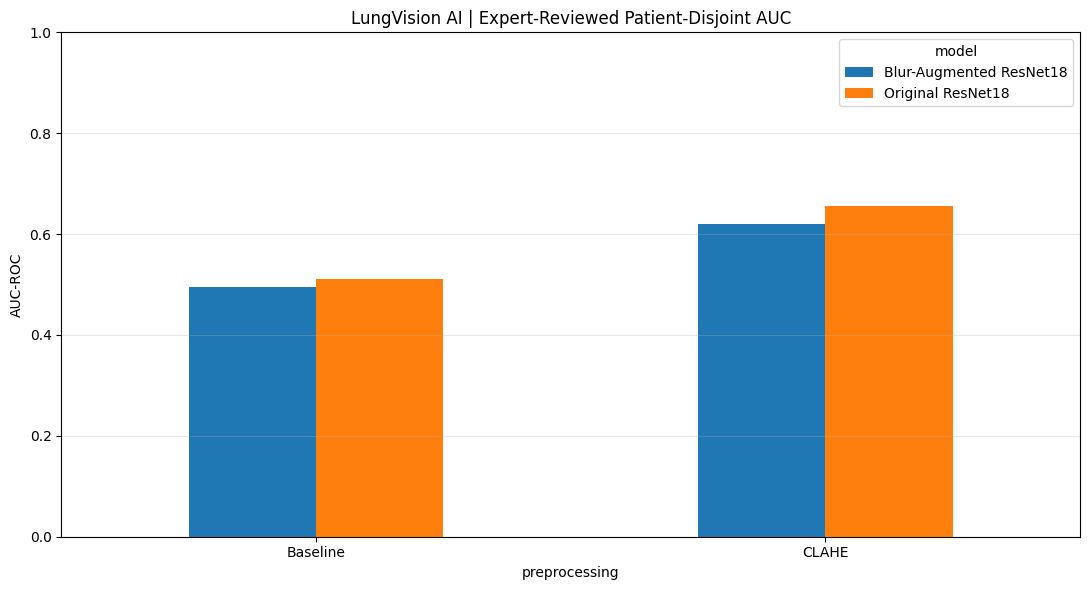


CELL 28.10 COMPLETED
Models evaluated: 2
Preprocessing conditions: 2
Expert images: 810
Patient-disjoint images: 810

Saved results:
/kaggle/working/lungvision_results/nih_expert_evaluation


In [8]:
# ============================================================
# CELL 28.10: NIH EXPERT-REVIEWED MODEL EVALUATION
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import cv2

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

from torchvision import models
from torchvision.transforms import functional as TF

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
BOOTSTRAP_REPS = 500

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

EXPERT_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/"
    "lungvision-nih-expert-labels"
)

NIH_ROOT = Path(
    "/kaggle/input/datasets/nih-chest-xrays"
)

RECOVERY_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "expert_image_recovery/images"
)

REGISTRY_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/"
    "lungvision/LungVision_AI_Model_Registry"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "nih_expert_evaluation"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

THRESHOLDS = {
    "Original ResNet18": {
        "default": 0.50,
        "IN-CXR locked": 0.1765
    },
    "Blur-Augmented ResNet18": {
        "default": 0.50,
        "IN-CXR locked": 0.1879
    }
}

# ------------------------------------------------------------
# 2. FIND AND LOAD EXPERT GROUND TRUTH
# ------------------------------------------------------------

label_candidates = list(
    EXPERT_ROOT.rglob(
        "*all_findings_expert_labels_test_labels.csv"
    )
)

if not label_candidates:
    raise FileNotFoundError(
        "Expert ground-truth CSV not found."
    )

expert = pd.read_csv(
    label_candidates[0],
    dtype=str
)

print("=" * 70)
print("LUNGVISION AI | EXPERT-REVIEWED EVALUATION")
print("=" * 70)

print("Expert records:", len(expert))

# ------------------------------------------------------------
# 3. NORMALIZE IMAGE AND PATIENT IDENTIFIERS
# ------------------------------------------------------------

def normalize_image_stem(value):

    if pd.isna(value):
        return None

    return Path(
        str(value).strip()
    ).stem.lower()


def normalize_patient(value):

    if pd.isna(value):
        return None

    value = str(value).strip()

    if value.endswith(".0"):
        value = value[:-2]

    return value


expert["image_stem"] = expert[
    "Image ID"
].apply(normalize_image_stem)

expert["patient_key"] = expert[
    "Patient ID"
].apply(normalize_patient)

# YES means abnormal; NO means normal
abnormal_mapping = {
    "YES": 1,
    "NO": 0,
    "ABNORMAL": 1,
    "NORMAL": 0,
    "1": 1,
    "0": 0
}

expert["true_label"] = (
    expert["Abnormal"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map(abnormal_mapping)
)

if expert["true_label"].isna().any():
    raise ValueError(
        "Unrecognized or missing expert Abnormal labels."
    )

expert["true_label"] = expert[
    "true_label"
].astype(int)

if expert["image_stem"].duplicated().any():
    raise ValueError(
        "Duplicate expert image identifiers found."
    )

# ------------------------------------------------------------
# 4. CREATE IMAGE LOOKUP
# ------------------------------------------------------------

print("\nBuilding image lookup...")

image_lookup = {}

for root in [NIH_ROOT, RECOVERY_DIR]:

    if not root.exists():
        continue

    for path in root.rglob("*"):

        if (
            path.is_file()
            and path.suffix.lower() in {
                ".png", ".jpg", ".jpeg"
            }
        ):

            image_lookup.setdefault(
                path.stem.lower(),
                path
            )

expert["resolved_image_path"] = (
    expert["image_stem"].map(image_lookup)
)

available = expert.dropna(
    subset=["resolved_image_path"]
).copy()

missing = expert[
    expert["resolved_image_path"].isna()
].copy()

print("Expert images:", len(expert))
print("Available images:", len(available))
print("Missing images:", len(missing))

if len(available) != 810 or len(missing) != 0:
    raise RuntimeError(
        "Expected all 810 expert images to be available."
    )

# ------------------------------------------------------------
# 5. VERIFY IMAGE INTEGRITY
# ------------------------------------------------------------

print("\nVerifying image integrity...")

for path in tqdm(
    available["resolved_image_path"],
    total=len(available)
):

    try:
        with Image.open(path) as image:
            image.verify()

    except Exception as exc:
        raise RuntimeError(
            f"Unreadable image: {path}"
        ) from exc

print("All 810 expert images are readable.")

# ------------------------------------------------------------
# 6. PATIENT-LEVEL OVERLAP AUDIT
# ------------------------------------------------------------

sample_csv = next(
    NIH_ROOT.rglob("sample_labels.csv"),
    None
)

if sample_csv is None:
    raise FileNotFoundError(
        "Existing NIH sample labels not found."
    )

sample_df = pd.read_csv(
    sample_csv,
    dtype=str
)

sample_patients = set(
    sample_df["Patient ID"]
    .apply(normalize_patient)
    .dropna()
)

expert["overlaps_previous_sample_patient"] = (
    expert["patient_key"].isin(sample_patients)
)

patient_disjoint = expert[
    ~expert["overlaps_previous_sample_patient"]
].copy()

print("\nPATIENT OVERLAP")

print("Total expert images:", len(expert))

print(
    "Images from previously used patients:",
    int(
        expert["overlaps_previous_sample_patient"].sum()
    )
)

print(
    "Patient-disjoint images:",
    len(patient_disjoint)
)

print(
    "Patient-disjoint unique patients:",
    patient_disjoint["patient_key"].nunique()
)

print(
    "All expert unique patients:",
    expert["patient_key"].nunique()
)

if patient_disjoint.empty:
    raise RuntimeError(
        "No patient-disjoint expert cohort remains."
    )

if patient_disjoint["true_label"].nunique() != 2:
    raise RuntimeError(
        "Patient-disjoint cohort does not contain both classes."
    )

# ------------------------------------------------------------
# 7. DEFINE PREPROCESSING METHODS
# ------------------------------------------------------------

def baseline_preprocessing(image):

    image = image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BILINEAR
    )

    return image


def clahe_preprocessing(image):

    array = np.asarray(
        image,
        dtype=np.uint8
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(array)

    image = Image.fromarray(enhanced)

    return image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BILINEAR
    )

PREPROCESSING = {
    "Baseline": baseline_preprocessing,
    "CLAHE": clahe_preprocessing
}

# ------------------------------------------------------------
# 8. DATASET
# ------------------------------------------------------------

class ExpertEvaluationDataset(Dataset):

    def __init__(self, dataframe, preprocessing):

        self.data = dataframe.reset_index(drop=True)
        self.preprocessing = preprocessing

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        with Image.open(
            row["resolved_image_path"]
        ) as image:

            image = image.convert("L")

            image = self.preprocessing(image)

            image = image.convert("RGB")

            tensor = TF.to_tensor(image)

            tensor = TF.normalize(
                tensor,
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )

        return tensor

# ------------------------------------------------------------
# 9. LOAD BOTH SAVED MODELS
# ------------------------------------------------------------

original_path = (
    REGISTRY_ROOT /
    "models/original_resnet18/model.pth"
)

augmented_path = (
    REGISTRY_ROOT /
    "models/blur_augmented_resnet18/model.pth"
)

def load_model(path):

    if not path.exists():
        raise FileNotFoundError(path)

    checkpoint = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    network = models.resnet18(
        weights=None
    )

    network.fc = nn.Linear(
        network.fc.in_features,
        1
    )

    network.load_state_dict(
        checkpoint["model_state_dict"]
    )

    network = network.to(DEVICE)
    network.eval()

    return network

models_to_evaluate = {
    "Original ResNet18": load_model(original_path),
    "Blur-Augmented ResNet18": load_model(augmented_path)
}

print("\nBoth checkpoints restored successfully.")

# ------------------------------------------------------------
# 10. INFERENCE
# ------------------------------------------------------------

probability_results = {}

for preprocessing_name, transform in PREPROCESSING.items():

    print("\nPREPROCESSING:", preprocessing_name)

    dataset = ExpertEvaluationDataset(
        expert,
        transform
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    model_probabilities = {
        name: [] for name in models_to_evaluate
    }

    with torch.inference_mode():

        for images in tqdm(
            loader,
            desc=preprocessing_name
        ):

            images = images.to(DEVICE)

            for model_name, network in models_to_evaluate.items():

                logits = network(images).flatten()

                probabilities = torch.sigmoid(
                    logits
                )

                model_probabilities[model_name].extend(
                    probabilities.cpu().numpy()
                )

    for model_name, probabilities in model_probabilities.items():

        key = f"{model_name} | {preprocessing_name}"

        probability_results[key] = np.asarray(
            probabilities,
            dtype=float
        )

# ------------------------------------------------------------
# 11. METRIC CALCULATION
# ------------------------------------------------------------

def evaluate_predictions(y_true, y_prob, threshold):

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "threshold": threshold,

        "auc_roc": roc_auc_score(
            y_true,
            y_prob
        ),

        "average_precision": average_precision_score(
            y_true,
            y_prob
        ),

        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "sensitivity": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if tn + fp else 0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "brier_score": brier_score_loss(
            y_true,
            y_prob
        ),

        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }

# ------------------------------------------------------------
# 12. EVALUATE FULL AND PATIENT-DISJOINT COHORTS
# ------------------------------------------------------------

all_results = []

cohorts = {
    "All 810 expert images": expert.reset_index(drop=True),
    "Patient-disjoint cohort": patient_disjoint.reset_index(drop=True)
}

for key, probabilities in probability_results.items():

    model_name, preprocessing_name = key.split(" | ")

    # Thresholds selected previously on IN-CXR.
    # For CLAHE, report only the default threshold:
    # CLAHE changes the input probability distribution.
    if preprocessing_name == "Baseline":

        threshold_config = THRESHOLDS[model_name]

    else:

        threshold_config = {
            "default": 0.50
        }

    for cohort_name, cohort in cohorts.items():

        indices = cohort.index.to_numpy()

        y_true = cohort[
            "true_label"
        ].to_numpy()

        y_prob = probabilities[indices]

        for threshold_name, threshold in threshold_config.items():

            metrics = evaluate_predictions(
                y_true,
                y_prob,
                threshold
            )

            metrics["model"] = model_name
            metrics["preprocessing"] = preprocessing_name
            metrics["cohort"] = cohort_name
            metrics["threshold_source"] = threshold_name

            all_results.append(metrics)

results_df = pd.DataFrame(all_results)

# ------------------------------------------------------------
# 13. PATIENT-CLUSTERED BOOTSTRAP
# ------------------------------------------------------------

def patient_bootstrap_auc(
    cohort,
    probabilities,
    repetitions=500,
    seed=42
):

    rng = np.random.default_rng(seed)

    y_true = cohort[
        "true_label"
    ].to_numpy()

    patient_ids = cohort[
        "patient_key"
    ].to_numpy()

    unique_patients = np.unique(patient_ids)

    patient_indices = {
        patient: np.where(
            patient_ids == patient
        )[0]
        for patient in unique_patients
    }

    auc_values = []

    for _ in range(repetitions):

        selected_patients = rng.choice(
            unique_patients,
            size=len(unique_patients),
            replace=True
        )

        indices = np.concatenate([
            patient_indices[p]
            for p in selected_patients
        ])

        target = y_true[indices]
        prediction = probabilities[indices]

        if len(np.unique(target)) < 2:
            continue

        auc_values.append(
            roc_auc_score(
                target,
                prediction
            )
        )

    if not auc_values:
        return np.nan, np.nan, np.nan

    return (
        float(np.mean(auc_values)),
        float(np.percentile(auc_values, 2.5)),
        float(np.percentile(auc_values, 97.5))
    )

bootstrap_results = []

for key, probabilities in probability_results.items():

    model_name, preprocessing_name = key.split(" | ")

    cohort = patient_disjoint.reset_index(drop=True)

    mean_auc, lower, upper = patient_bootstrap_auc(
        cohort,
        probabilities[cohort.index.to_numpy()],
        repetitions=BOOTSTRAP_REPS,
        seed=SEED
    )

    bootstrap_results.append({
        "model": model_name,
        "preprocessing": preprocessing_name,
        "patient_disjoint_auc": roc_auc_score(
            cohort["true_label"],
            probabilities
        ),
        "bootstrap_mean_auc": mean_auc,
        "auc_ci_lower_95": lower,
        "auc_ci_upper_95": upper,
        "bootstrap_repetitions": BOOTSTRAP_REPS
    })

bootstrap_df = pd.DataFrame(
    bootstrap_results
)

# ------------------------------------------------------------
# 14. SAVE PREDICTIONS
# ------------------------------------------------------------

prediction_export = expert[
    [
        "Image ID",
        "Patient ID",
        "true_label",
        "overlaps_previous_sample_patient",
        "resolved_image_path"
    ]
].copy()

for key, probabilities in probability_results.items():

    column = key.lower().replace(" | ", "_").replace(" ", "_")

    prediction_export[column + "_probability"] = probabilities

prediction_export.to_csv(
    OUTPUT_DIR / "expert_image_predictions.csv",
    index=False
)

results_df.to_csv(
    OUTPUT_DIR / "expert_evaluation_metrics.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR / "patient_clustered_bootstrap_auc.csv",
    index=False
)

expert.to_csv(
    OUTPUT_DIR / "expert_810_evaluation_manifest.csv",
    index=False
)

# ------------------------------------------------------------
# 15. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXPERT-REVIEWED EVALUATION RESULTS")
print("=" * 70)

print("Total expert images:", len(expert))
print("Unique expert patients:", expert["patient_key"].nunique())
print("Patient-disjoint images:", len(patient_disjoint))
print("Patient-disjoint patients:", patient_disjoint["patient_key"].nunique())

print("\nCLASS DISTRIBUTION")

print(
    expert["true_label"]
    .value_counts()
    .rename({
        0: "Normal",
        1: "Abnormal"
    })
)

print("\nFULL EVALUATION METRICS")

display(
    results_df.round(4)
)

print("\nPATIENT-CLUSTERED AUC CONFIDENCE INTERVALS")

display(
    bootstrap_df.round(4)
)

# ------------------------------------------------------------
# 16. PLOT PATIENT-DISJOINT AUC
# ------------------------------------------------------------

plot_df = results_df[
    results_df["cohort"] == "Patient-disjoint cohort"
].copy()

plot_df = plot_df[
    plot_df["threshold_source"] == "default"
]

plot_pivot = plot_df.pivot(
    index="preprocessing",
    columns="model",
    values="auc_roc"
)

plot_pivot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "LungVision AI | Expert-Reviewed Patient-Disjoint AUC"
)

plt.ylabel("AUC-ROC")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "expert_patient_disjoint_auc.png",
    dpi=180
)

plt.show()

# ------------------------------------------------------------
# 17. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 28.10 COMPLETED")
print("=" * 70)

print("Models evaluated:", len(models_to_evaluate))
print("Preprocessing conditions:", len(PREPROCESSING))
print("Expert images:", len(expert))
print("Patient-disjoint images:", len(patient_disjoint))

print("\nSaved results:")
print(OUTPUT_DIR)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Saved prediction rows: 810

IMAGE ALIGNMENT
_merge
both          810
left_only       0
right_only      0
Name: count, dtype: int64
Patient ID mismatches: 0

OVERLAP RECONCILIATION
Exact images in previously used NIH sample: 27
Images belonging to previously used patients: 474
Unique overlapping patients: 256
Exact-overlap images with patient overlap: 27

COHORT SUMMARY

 All expert images
Images: 810
Unique patients: 532
Normal: 232
Abnormal: 578

 Patient-disjoint
Images: 336
Unique patients: 276
Normal: 144
Abnormal: 192

SAVED PROBABILITY COLUMNS
original_resnet18_baseline_probability
blur-augmented_resnet18_baseline_probability
original_resnet18_clahe_probability
blur-augmented_resnet18_clahe_probability

CORRECTED EXPERT EVALUATION


,threshold,auc_roc,average_precision,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,brier_score,tn,fp,fn,tp,model,preprocessing,cohort,threshold_source,images,patients
0,0.5000,0.5104,0.7231,0.4272,0.5057,0.7209,0.3218,0.6897,0.4450,0.4270,160,72,392,186,Original ResNet18,Baseline,All 810 expert images,Default 0.50,810,532
1,0.1765,0.5104,0.7231,0.5383,0.5036,0.7161,0.5848,0.4224,0.6438,0.4270,98,134,240,338,Original ResNet18,Baseline,All 810 expert images,IN-CXR locked,810,532
2,0.5000,0.4931,0.5606,0.4792,0.5017,0.5739,0.3438,0.6597,0.4300,0.3867,95,49,126,66,Original ResNet18,Baseline,Patient-disjoint cohort,Default 0.50,336,276
3,0.1765,0.4931,0.5606,0.5119,0.4991,0.5707,0.5885,0.4097,0.5795,0.3867,59,85,79,113,Original ResNet18,Baseline,Patient-disjoint cohort,IN-CXR locked,336,276
4,0.5000,0.6551,0.8304,0.6173,0.5990,0.7827,0.6419,0.5560,0.7053,0.2669,129,103,207,371,Original ResNet18,CLAHE,All 810 expert images,Default 0.50,810,532
5,0.5000,0.6097,0.6958,0.5744,0.5712,0.6369,0.5938,0.5486,0.6146,0.3021,79,65,78,114,Original ResNet18,CLAHE,Patient-disjoint cohort,Default 0.50,336,276
6,0.5000,0.4955,0.7167,0.5432,0.5058,0.7176,0.5934,0.4181,0.6496,0.3447,97,135,235,343,Blur-Augmented ResNet18,Baseline,All 810 expert images,Default 0.50,810,532
7,0.1879,0.4955,0.7167,0.6259,0.5005,0.7138,0.7941,0.2069,0.7518,0.3447,48,184,119,459,Blur-Augmented ResNet18,Baseline,All 810 expert images,IN-CXR locked,810,532
8,0.5000,0.4677,0.5510,0.5089,0.4922,0.5652,0.6094,0.3750,0.5865,0.3841,54,90,75,117,Blur-Augmented ResNet18,Baseline,Patient-disjoint cohort,Default 0.50,336,276
9,0.1879,0.4677,0.5510,0.5208,0.4757,0.5568,0.7917,0.1597,0.6538,0.3841,23,121,40,152,Blur-Augmented ResNet18,Baseline,Patient-disjoint cohort,IN-CXR locked,336,276



PATIENT-CLUSTERED BOOTSTRAP


,bootstrap_mean_auc,ci_lower_95,ci_upper_95,valid_replicates,model,preprocessing,cohort
0,0.4932,0.4239,0.5656,1000,Original ResNet18,Baseline,Patient-disjoint
1,0.6096,0.5415,0.6814,1000,Original ResNet18,CLAHE,Patient-disjoint
2,0.4676,0.3966,0.5404,1000,Blur-Augmented ResNet18,Baseline,Patient-disjoint
3,0.5859,0.5174,0.6569,1000,Blur-Augmented ResNet18,CLAHE,Patient-disjoint


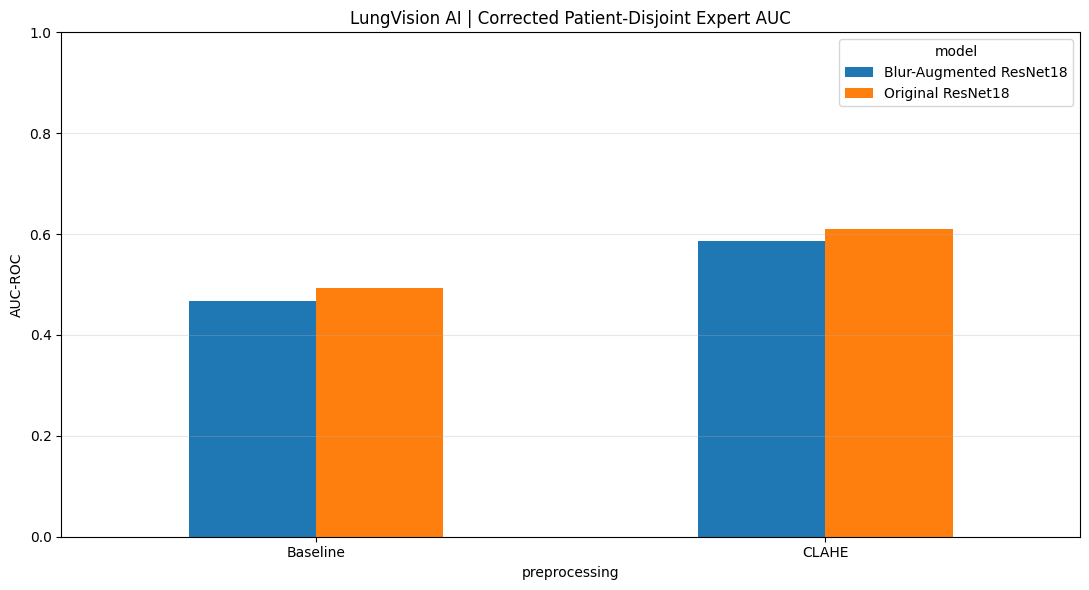


CELL 28.10.1 COMPLETED
Expert images: 810
Patient-disjoint images: 336
Patient-disjoint patients: 276

Results saved: /kaggle/working/lungvision_results/corrected_expert_evaluation


In [9]:
# ============================================================
# CELL 28.10.1: CORRECTED EXPERT EVALUATION
# IMAGE AND PATIENT ALIGNMENT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

BASE_DIR = Path(
    "/kaggle/working/lungvision_results"
)

EVAL_DIR = BASE_DIR / "nih_expert_evaluation"

NIH_ROOT = Path(
    "/kaggle/input/datasets/nih-chest-xrays"
)

OUTPUT_DIR = BASE_DIR / "corrected_expert_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BOOTSTRAP_REPS = 1000
SEED = 42

LOCKED_THRESHOLDS = {
    "Original ResNet18": 0.1765,
    "Blur-Augmented ResNet18": 0.1879
}

# ------------------------------------------------------------
# 2. LOAD SAVED PREDICTIONS
# ------------------------------------------------------------

PRED_PATH = (
    EVAL_DIR / "expert_image_predictions.csv"
)

if not PRED_PATH.exists():
    raise FileNotFoundError(PRED_PATH)

pred = pd.read_csv(PRED_PATH)

print("Saved prediction rows:", len(pred))

# ------------------------------------------------------------
# 3. LOAD SOURCE METADATA
# ------------------------------------------------------------

EXPERT_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/"
    "lungvision-nih-expert-labels"
)

label_path = next(
    EXPERT_ROOT.rglob(
        "*all_findings_expert_labels_test_labels.csv"
    )
)

expert = pd.read_csv(
    label_path,
    dtype=str
)

sample_path = next(
    NIH_ROOT.rglob("sample_labels.csv")
)

sample = pd.read_csv(
    sample_path,
    dtype=str
)

# ------------------------------------------------------------
# 4. IDENTIFIER NORMALIZATION
# ------------------------------------------------------------

def image_stem(value):

    if pd.isna(value):
        return None

    return Path(
        str(value).strip()
    ).stem.lower()


def normalize_patient(value):

    if pd.isna(value):
        return None

    value = str(value).strip()

    if value.endswith(".0"):
        value = value[:-2]

    # Normalize numeric IDs with possible leading zeros
    if value.isdigit():
        return str(int(value))

    return value


pred["image_key"] = pred["Image ID"].apply(
    image_stem
)

pred["patient_key"] = pred["Patient ID"].apply(
    normalize_patient
)

expert["image_key"] = expert["Image ID"].apply(
    image_stem
)

expert["patient_key"] = expert["Patient ID"].apply(
    normalize_patient
)

sample["image_key"] = sample["Image Index"].apply(
    image_stem
)

sample["patient_key"] = sample["Patient ID"].apply(
    normalize_patient
)

# ------------------------------------------------------------
# 5. VERIFY PREDICTION / EXPERT LABEL ALIGNMENT
# ------------------------------------------------------------

expert_check = expert[
    ["image_key", "patient_key", "Abnormal"]
].copy()

alignment = pred.merge(
    expert_check,
    on="image_key",
    how="outer",
    suffixes=("_prediction", "_expert"),
    indicator=True,
    validate="one_to_one"
)

print("\nIMAGE ALIGNMENT")

print(alignment["_merge"].value_counts())

if not alignment["_merge"].eq("both").all():
    raise RuntimeError(
        "Prediction files and expert labels do not align."
    )

patient_match = (
    alignment["patient_key_prediction"]
    == alignment["patient_key_expert"]
)

print(
    "Patient ID mismatches:",
    int((~patient_match).sum())
)

if not patient_match.all():
    raise RuntimeError(
        "Expert patient IDs disagree with prediction metadata."
    )

# ------------------------------------------------------------
# 6. RECOMPUTE EXACT IMAGE AND PATIENT OVERLAP
# ------------------------------------------------------------

sample_image_ids = set(
    sample["image_key"].dropna()
)

sample_patient_ids = set(
    sample["patient_key"].dropna()
)

pred["exact_image_overlap"] = (
    pred["image_key"].isin(sample_image_ids)
)

pred["previous_patient_overlap"] = (
    pred["patient_key"].isin(sample_patient_ids)
)

print("\nOVERLAP RECONCILIATION")

print(
    "Exact images in previously used NIH sample:",
    int(pred["exact_image_overlap"].sum())
)

print(
    "Images belonging to previously used patients:",
    int(pred["previous_patient_overlap"].sum())
)

print(
    "Unique overlapping patients:",
    pred.loc[
        pred["previous_patient_overlap"],
        "patient_key"
    ].nunique()
)

print(
    "Exact-overlap images with patient overlap:",
    int(
        (
            pred["exact_image_overlap"]
            & pred["previous_patient_overlap"]
        ).sum()
    )
)

if (
    pred["exact_image_overlap"]
    & ~pred["previous_patient_overlap"]
).any():
    print(
        "WARNING: Exact-image overlap exists without "
        "matching patient IDs. Investigate before final reporting."
    )

# ------------------------------------------------------------
# 7. BUILD CORRECT COHORTS
# ------------------------------------------------------------

pred["true_label"] = pd.to_numeric(
    pred["true_label"],
    errors="raise"
).astype(int)

# Keep the original prediction rows; do not reset
# and then reuse their old prediction-array indices.

all_cohort = pred.copy()

disjoint_cohort = pred[
    ~pred["previous_patient_overlap"]
].copy()

print("\nCOHORT SUMMARY")

for name, cohort in [
    ("All expert images", all_cohort),
    ("Patient-disjoint", disjoint_cohort)
]:

    print("\n", name)

    print("Images:", len(cohort))

    print(
        "Unique patients:",
        cohort["patient_key"].nunique()
    )

    print(
        "Normal:",
        int((cohort["true_label"] == 0).sum())
    )

    print(
        "Abnormal:",
        int((cohort["true_label"] == 1).sum())
    )

    if cohort["true_label"].nunique() < 2:
        raise RuntimeError(
            f"{name} does not contain both classes."
        )

# ------------------------------------------------------------
# 8. IDENTIFY SAVED MODEL PROBABILITY COLUMNS
# ------------------------------------------------------------

probability_columns = [
    c for c in pred.columns
    if c.endswith("_probability")
]

print("\nSAVED PROBABILITY COLUMNS")

for col in probability_columns:
    print(col)

required_columns = [
    "original_resnet18_baseline_probability",
    "original_resnet18_clahe_probability",
    "blur-augmented_resnet18_baseline_probability",
    "blur-augmented_resnet18_clahe_probability"
]

missing = [
    c for c in required_columns
    if c not in pred.columns
]

if missing:
    raise ValueError(
        f"Missing prediction columns: {missing}"
    )

# ------------------------------------------------------------
# 9. DEFINE EXPERIMENTS
# ------------------------------------------------------------

experiments = [
    {
        "model": "Original ResNet18",
        "preprocessing": "Baseline",
        "column": "original_resnet18_baseline_probability"
    },
    {
        "model": "Original ResNet18",
        "preprocessing": "CLAHE",
        "column": "original_resnet18_clahe_probability"
    },
    {
        "model": "Blur-Augmented ResNet18",
        "preprocessing": "Baseline",
        "column": "blur-augmented_resnet18_baseline_probability"
    },
    {
        "model": "Blur-Augmented ResNet18",
        "preprocessing": "CLAHE",
        "column": "blur-augmented_resnet18_clahe_probability"
    }
]

# ------------------------------------------------------------
# 10. METRICS
# ------------------------------------------------------------

def evaluate_metrics(
    cohort,
    probability_column,
    threshold
):

    y_true = cohort["true_label"].to_numpy()

    y_prob = cohort[
        probability_column
    ].to_numpy(dtype=float)

    if not np.isfinite(y_prob).all():
        raise ValueError("Invalid probabilities found.")

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "threshold": threshold,

        "auc_roc": roc_auc_score(
            y_true,
            y_prob
        ),

        "average_precision": average_precision_score(
            y_true,
            y_prob
        ),

        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "sensitivity": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if tn + fp else 0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "brier_score": brier_score_loss(
            y_true,
            y_prob
        ),

        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }


# ------------------------------------------------------------
# 11. EVALUATE FULL AND DISJOINT COHORTS
# ------------------------------------------------------------

results = []

cohorts = {
    "All 810 expert images": all_cohort,
    "Patient-disjoint cohort": disjoint_cohort
}

for experiment in experiments:

    model_name = experiment["model"]
    preprocessing = experiment["preprocessing"]
    probability_column = experiment["column"]

    if preprocessing == "Baseline":

        thresholds = {
            "Default 0.50": 0.50,
            "IN-CXR locked": LOCKED_THRESHOLDS[model_name]
        }

    else:

        # CLAHE changes input and output distributions.
        # Do not transfer the baseline calibrated threshold.
        thresholds = {
            "Default 0.50": 0.50
        }

    for cohort_name, cohort in cohorts.items():

        for threshold_name, threshold in thresholds.items():

            metrics = evaluate_metrics(
                cohort,
                probability_column,
                threshold
            )

            metrics.update({
                "model": model_name,
                "preprocessing": preprocessing,
                "cohort": cohort_name,
                "threshold_source": threshold_name,
                "images": len(cohort),
                "patients": cohort["patient_key"].nunique()
            })

            results.append(metrics)

results_df = pd.DataFrame(results)

print("\nCORRECTED EXPERT EVALUATION")

display(results_df.round(4))

# ------------------------------------------------------------
# 12. PATIENT-CLUSTERED BOOTSTRAP
# ------------------------------------------------------------

def patient_bootstrap(
    cohort,
    probability_column,
    repetitions=1000,
    seed=42
):

    rng = np.random.default_rng(seed)

    y_true = cohort["true_label"].to_numpy()

    y_prob = cohort[
        probability_column
    ].to_numpy(dtype=float)

    patient_ids = cohort[
        "patient_key"
    ].to_numpy()

    unique_patients = np.unique(
        patient_ids
    )

    patient_indices = {
        patient: np.where(
            patient_ids == patient
        )[0]
        for patient in unique_patients
    }

    values = []

    for _ in range(repetitions):

        selected = rng.choice(
            unique_patients,
            size=len(unique_patients),
            replace=True
        )

        indices = np.concatenate([
            patient_indices[p]
            for p in selected
        ])

        yt = y_true[indices]
        yp = y_prob[indices]

        if len(np.unique(yt)) < 2:
            continue

        values.append(
            roc_auc_score(yt, yp)
        )

    values = np.asarray(values)

    return {
        "bootstrap_mean_auc": float(values.mean()),
        "ci_lower_95": float(
            np.percentile(values, 2.5)
        ),
        "ci_upper_95": float(
            np.percentile(values, 97.5)
        ),
        "valid_replicates": len(values)
    }


bootstrap_results = []

for experiment in experiments:

    result = patient_bootstrap(
        disjoint_cohort,
        experiment["column"],
        repetitions=BOOTSTRAP_REPS,
        seed=SEED
    )

    result.update({
        "model": experiment["model"],
        "preprocessing": experiment["preprocessing"],
        "cohort": "Patient-disjoint"
    })

    bootstrap_results.append(result)

bootstrap_df = pd.DataFrame(
    bootstrap_results
)

print("\nPATIENT-CLUSTERED BOOTSTRAP")

display(
    bootstrap_df.round(4)
)

# ------------------------------------------------------------
# 13. PLOT CORRECT PATIENT-DISJOINT AUC
# ------------------------------------------------------------

plot_df = results_df[
    (results_df["cohort"] == "Patient-disjoint cohort")
    & (results_df["threshold_source"] == "Default 0.50")
].copy()

pivot = plot_df.pivot(
    index="preprocessing",
    columns="model",
    values="auc_roc"
)

pivot = pivot.reindex([
    "Baseline",
    "CLAHE"
])

pivot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "LungVision AI | Corrected Patient-Disjoint Expert AUC"
)

plt.ylabel("AUC-ROC")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "corrected_patient_disjoint_auc.png",
    dpi=180
)

plt.show()

# ------------------------------------------------------------
# 14. EXPORT CORRECTED RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    OUTPUT_DIR / "corrected_expert_metrics.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR / "corrected_patient_bootstrap.csv",
    index=False
)

pred.to_csv(
    OUTPUT_DIR / "verified_expert_predictions.csv",
    index=False
)

disjoint_cohort.to_csv(
    OUTPUT_DIR / "verified_patient_disjoint_cohort.csv",
    index=False
)

print("\n" + "=" * 70)
print("CELL 28.10.1 COMPLETED")
print("=" * 70)

print("Expert images:", len(all_cohort))
print("Patient-disjoint images:", len(disjoint_cohort))
print("Patient-disjoint patients:", disjoint_cohort["patient_key"].nunique())

print("\nResults saved:", OUTPUT_DIR)

In [10]:
# ============================================================
# CELL 28.10.2: FINAL EXPERT RESULTS SUMMARY
# ============================================================

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "corrected_expert_evaluation"
)

metrics = pd.read_csv(
    OUTPUT_DIR / "corrected_expert_metrics.csv"
)

bootstrap = pd.read_csv(
    OUTPUT_DIR / "corrected_patient_bootstrap.csv"
)

# AUC comparison at default threshold
auc_summary = metrics[
    metrics["threshold_source"] == "Default 0.50"
][[
    "model",
    "preprocessing",
    "cohort",
    "images",
    "patients",
    "auc_roc",
    "average_precision",
    "accuracy",
    "sensitivity",
    "specificity",
    "f1"
]]

print("=" * 70)
print("LUNGVISION AI | FINAL EXPERT EVALUATION")
print("=" * 70)

display(
    auc_summary.round(4)
)

print("\nPATIENT-CLUSTERED CONFIDENCE INTERVALS")

display(
    bootstrap.round(4)
)

print("\nFULL RESULTS INCLUDING LOCKED THRESHOLDS")

display(
    metrics.round(4)
)

print("\nAll result files are already saved.")

LUNGVISION AI | FINAL EXPERT EVALUATION


,model,preprocessing,cohort,images,patients,auc_roc,average_precision,accuracy,sensitivity,specificity,f1
0,Original ResNet18,Baseline,All 810 expert images,810,532,0.5104,0.7231,0.4272,0.3218,0.6897,0.4450
2,Original ResNet18,Baseline,Patient-disjoint cohort,336,276,0.4931,0.5606,0.4792,0.3438,0.6597,0.4300
4,Original ResNet18,CLAHE,All 810 expert images,810,532,0.6551,0.8304,0.6173,0.6419,0.5560,0.7053
5,Original ResNet18,CLAHE,Patient-disjoint cohort,336,276,0.6097,0.6958,0.5744,0.5938,0.5486,0.6146
6,Blur-Augmented ResNet18,Baseline,All 810 expert images,810,532,0.4955,0.7167,0.5432,0.5934,0.4181,0.6496
8,Blur-Augmented ResNet18,Baseline,Patient-disjoint cohort,336,276,0.4677,0.5510,0.5089,0.6094,0.3750,0.5865
10,Blur-Augmented ResNet18,CLAHE,All 810 expert images,810,532,0.6200,0.8042,0.6827,0.8443,0.2802,0.7916
11,Blur-Augmented ResNet18,CLAHE,Patient-disjoint cohort,336,276,0.5857,0.6634,0.5714,0.8177,0.2431,0.6856



PATIENT-CLUSTERED CONFIDENCE INTERVALS


,bootstrap_mean_auc,ci_lower_95,ci_upper_95,valid_replicates,model,preprocessing,cohort
0,0.4932,0.4239,0.5656,1000,Original ResNet18,Baseline,Patient-disjoint
1,0.6096,0.5415,0.6814,1000,Original ResNet18,CLAHE,Patient-disjoint
2,0.4676,0.3966,0.5404,1000,Blur-Augmented ResNet18,Baseline,Patient-disjoint
3,0.5859,0.5174,0.6569,1000,Blur-Augmented ResNet18,CLAHE,Patient-disjoint



FULL RESULTS INCLUDING LOCKED THRESHOLDS


,threshold,auc_roc,average_precision,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,brier_score,tn,fp,fn,tp,model,preprocessing,cohort,threshold_source,images,patients
0,0.5000,0.5104,0.7231,0.4272,0.5057,0.7209,0.3218,0.6897,0.4450,0.4270,160,72,392,186,Original ResNet18,Baseline,All 810 expert images,Default 0.50,810,532
1,0.1765,0.5104,0.7231,0.5383,0.5036,0.7161,0.5848,0.4224,0.6438,0.4270,98,134,240,338,Original ResNet18,Baseline,All 810 expert images,IN-CXR locked,810,532
2,0.5000,0.4931,0.5606,0.4792,0.5017,0.5739,0.3438,0.6597,0.4300,0.3867,95,49,126,66,Original ResNet18,Baseline,Patient-disjoint cohort,Default 0.50,336,276
3,0.1765,0.4931,0.5606,0.5119,0.4991,0.5707,0.5885,0.4097,0.5795,0.3867,59,85,79,113,Original ResNet18,Baseline,Patient-disjoint cohort,IN-CXR locked,336,276
4,0.5000,0.6551,0.8304,0.6173,0.5990,0.7827,0.6419,0.5560,0.7053,0.2669,129,103,207,371,Original ResNet18,CLAHE,All 810 expert images,Default 0.50,810,532
5,0.5000,0.6097,0.6958,0.5744,0.5712,0.6369,0.5938,0.5486,0.6146,0.3021,79,65,78,114,Original ResNet18,CLAHE,Patient-disjoint cohort,Default 0.50,336,276
6,0.5000,0.4955,0.7167,0.5432,0.5058,0.7176,0.5934,0.4181,0.6496,0.3447,97,135,235,343,Blur-Augmented ResNet18,Baseline,All 810 expert images,Default 0.50,810,532
7,0.1879,0.4955,0.7167,0.6259,0.5005,0.7138,0.7941,0.2069,0.7518,0.3447,48,184,119,459,Blur-Augmented ResNet18,Baseline,All 810 expert images,IN-CXR locked,810,532
8,0.5000,0.4677,0.5510,0.5089,0.4922,0.5652,0.6094,0.3750,0.5865,0.3841,54,90,75,117,Blur-Augmented ResNet18,Baseline,Patient-disjoint cohort,Default 0.50,336,276
9,0.1879,0.4677,0.5510,0.5208,0.4757,0.5568,0.7917,0.1597,0.6538,0.3841,23,121,40,152,Blur-Augmented ResNet18,Baseline,Patient-disjoint cohort,IN-CXR locked,336,276



All result files are already saved.


LUNGVISION AI | SELF-CONTAINED EXPERT EVALUATION
Device: cuda
GPU: Tesla T4

Expert images: 810
Unique patients: 532

LOCAL IMAGE AVAILABILITY
Available: 810
Missing: 0

All expert images are available: 810

Verifying image integrity...


  0%|          | 0/810 [00:00<?, ?it/s]

Image integrity verified.

PATIENT-LEVEL COHORT
All expert images: 810
Previously used patient images: 474
Patient-disjoint images: 336
Patient-disjoint patients: 276
Remaining overlapping patients: 0

Both model checkpoints verified.

PREPROCESSING: Baseline

Evaluating: Original ResNet18


Original ResNet18:   0%|          | 0/26 [00:00<?, ?it/s]


Evaluating: Blur-Augmented ResNet18


Blur-Augmented ResNet18:   0%|          | 0/26 [00:00<?, ?it/s]

... (4 outputs left out)


Regenerated prediction file: /kaggle/working/lungvision_results/final_expert_statistical_analysis/expert_image_predictions.csv

EXPERT EVALUATION METRICS


,threshold,auc_roc,average_precision,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,brier_score,tn,fp,fn,tp,model,preprocessing,cohort,threshold_source,images,patients
0,0.5000,0.5104,0.7231,0.4272,0.5057,0.7209,0.3218,0.6897,0.4450,0.4270,160,72,392,186,Original ResNet18,Baseline,All 810 expert images,Default 0.50,810,532
1,0.1765,0.5104,0.7231,0.5383,0.5036,0.7161,0.5848,0.4224,0.6438,0.4270,98,134,240,338,Original ResNet18,Baseline,All 810 expert images,IN-CXR locked,810,532
2,0.5000,0.4931,0.5606,0.4792,0.5017,0.5739,0.3438,0.6597,0.4300,0.3867,95,49,126,66,Original ResNet18,Baseline,Patient-disjoint cohort,Default 0.50,336,276
3,0.1765,0.4931,0.5606,0.5119,0.4991,0.5707,0.5885,0.4097,0.5795,0.3867,59,85,79,113,Original ResNet18,Baseline,Patient-disjoint cohort,IN-CXR locked,336,276
4,0.5000,0.4955,0.7167,0.5432,0.5058,0.7176,0.5934,0.4181,0.6496,0.3447,97,135,235,343,Blur-Augmented ResNet18,Baseline,All 810 expert images,Default 0.50,810,532
5,0.1879,0.4955,0.7167,0.6259,0.5005,0.7138,0.7941,0.2069,0.7518,0.3447,48,184,119,459,Blur-Augmented ResNet18,Baseline,All 810 expert images,IN-CXR locked,810,532
6,0.5000,0.4677,0.5510,0.5089,0.4922,0.5652,0.6094,0.3750,0.5865,0.3841,54,90,75,117,Blur-Augmented ResNet18,Baseline,Patient-disjoint cohort,Default 0.50,336,276
7,0.1879,0.4677,0.5510,0.5208,0.4757,0.5568,0.7917,0.1597,0.6538,0.3841,23,121,40,152,Blur-Augmented ResNet18,Baseline,Patient-disjoint cohort,IN-CXR locked,336,276
8,0.5000,0.6551,0.8304,0.6173,0.5990,0.7827,0.6419,0.5560,0.7053,0.2669,129,103,207,371,Original ResNet18,CLAHE,All 810 expert images,Default 0.50,810,532
9,0.5000,0.6097,0.6958,0.5744,0.5712,0.6369,0.5938,0.5486,0.6146,0.3021,79,65,78,114,Original ResNet18,CLAHE,Patient-disjoint cohort,Default 0.50,336,276



PAIRED PATIENT-CLUSTERED AUC COMPARISON


,comparison,auc_a,auc_b,observed_auc_difference,ci_lower_95,ci_upper_95,valid_repetitions
0,Original CLAHE vs Original Baseline,0.6097,0.4931,0.1166,0.0808,0.1559,2000
1,Augmented CLAHE vs Augmented Baseline,0.5857,0.4677,0.1180,0.0783,0.1568,2000
2,Original CLAHE vs Augmented CLAHE,0.6097,0.5857,0.0240,0.0044,0.0443,2000


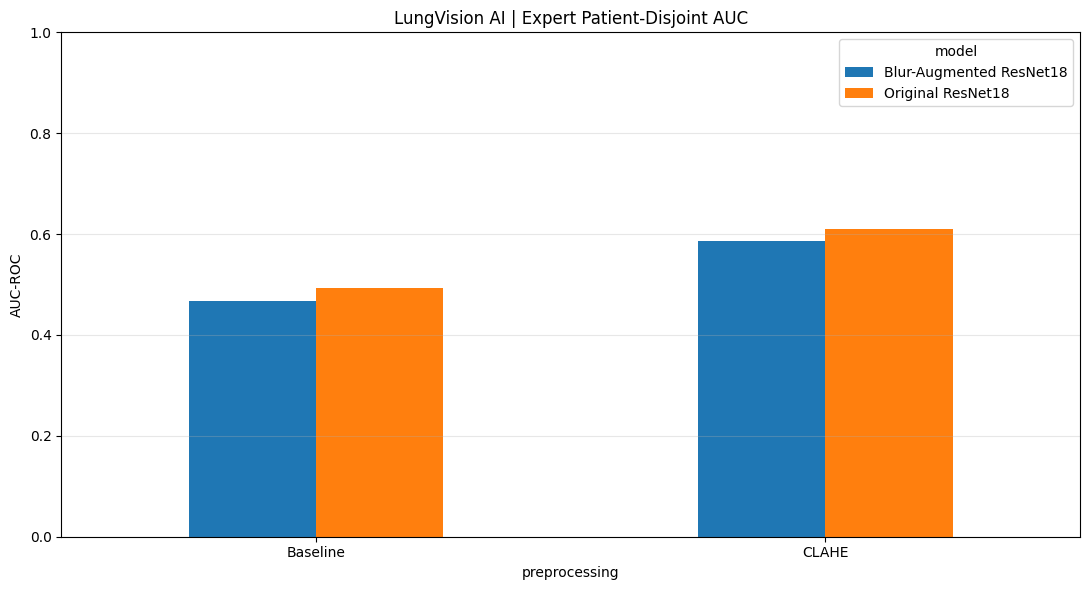


CELL 28.11 COMPLETED SUCCESSFULLY
Expert images: 810
All expert patients: 532
Patient-disjoint images: 336
Patient-disjoint patients: 276

Prediction file:
/kaggle/working/lungvision_results/final_expert_statistical_analysis/expert_image_predictions.csv

Results directory:
/kaggle/working/lungvision_results/final_expert_statistical_analysis


In [11]:
# ============================================================
# CELL 28.11: SELF-CONTAINED EXPERT EVALUATION RECOVERY
# REGENERATE PREDICTIONS + PAIRED PATIENT BOOTSTRAP
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import cv2
import requests
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from io import BytesIO
from urllib.parse import quote
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

from torchvision import models
from torchvision.transforms import functional as TF
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
N_BOOTSTRAP = 2000

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

EXPERT_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/"
    "lungvision-nih-expert-labels"
)

NIH_ROOT = Path(
    "/kaggle/input/datasets/nih-chest-xrays"
)

RECOVERY_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "expert_image_recovery/images"
)

REGISTRY_ROOT = Path(
    "/kaggle/input/datasets/babulkumar07/"
    "lungvision/LungVision_AI_Model_Registry"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "final_expert_statistical_analysis"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

torch.manual_seed(SEED)
np.random.seed(SEED)

# Thresholds previously selected using IN-CXR validation.
LOCKED_THRESHOLDS = {
    "Original ResNet18": 0.1765,
    "Blur-Augmented ResNet18": 0.1879
}

print("=" * 70)
print("LUNGVISION AI | SELF-CONTAINED EXPERT EVALUATION")
print("=" * 70)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 2. LOAD EXPERT GROUND-TRUTH LABELS
# ============================================================

label_candidates = list(
    EXPERT_ROOT.rglob(
        "*all_findings_expert_labels_test_labels.csv"
    )
)

if not label_candidates:
    raise FileNotFoundError(
        "Expert ground-truth CSV not found."
    )

expert = pd.read_csv(
    label_candidates[0],
    dtype=str
)

def normalize_image_stem(value):

    return Path(
        str(value).strip()
    ).stem.lower()


def normalize_patient_id(value):

    if pd.isna(value):
        return None

    value = str(value).strip()

    if value.endswith(".0"):
        value = value[:-2]

    if value.isdigit():
        return str(int(value))

    return value


expert["image_stem"] = expert[
    "Image ID"
].apply(normalize_image_stem)

expert["patient_key"] = expert[
    "Patient ID"
].apply(normalize_patient_id)

expert["true_label"] = (
    expert["Abnormal"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({
        "YES": 1,
        "NO": 0
    })
)

if expert["true_label"].isna().any():
    raise ValueError(
        "Invalid expert Abnormal labels."
    )

expert["true_label"] = expert[
    "true_label"
].astype(int)

print("\nExpert images:", len(expert))
print("Unique patients:", expert["patient_key"].nunique())


# ============================================================
# 3. LOCATE ALL AVAILABLE EXPERT IMAGES
# ============================================================

RECOVERY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

image_lookup = {}

for root in [
    NIH_ROOT,
    RECOVERY_DIR
]:

    if not root.exists():
        continue

    for path in root.rglob("*"):

        if (
            path.is_file()
            and path.suffix.lower() in {
                ".png", ".jpg", ".jpeg"
            }
        ):

            image_lookup.setdefault(
                path.stem.lower(),
                path
            )

expert["resolved_image_path"] = (
    expert["image_stem"].map(image_lookup)
)

missing = expert[
    expert["resolved_image_path"].isna()
].copy()

print("\nLOCAL IMAGE AVAILABILITY")

print(
    "Available:",
    expert["resolved_image_path"].notna().sum()
)

print("Missing:", len(missing))


# ============================================================
# 4. RECOVER MISSING IMAGES FROM PUBLIC GCS
# ============================================================

if len(missing):

    print("\nRecovering missing expert images...")

    GCS_PREFIX = (
        "https://storage.googleapis.com/"
        "healthai-us/nih-cxr-14/png/"
    )

    def download_image(row):

        filename = Path(
            str(row["Image ID"])
        ).name

        if not Path(filename).suffix:
            filename += ".png"

        destination = RECOVERY_DIR / filename

        if destination.exists():
            return row["image_stem"], destination

        url = GCS_PREFIX + quote(filename)

        try:

            response = requests.get(
                url,
                timeout=60
            )

            if response.status_code != 200:
                raise RuntimeError(
                    f"HTTP {response.status_code}"
                )

            image = Image.open(
                BytesIO(response.content)
            )

            image.verify()

            destination.write_bytes(
                response.content
            )

            return row["image_stem"], destination

        except Exception as exc:

            return row["image_stem"], str(exc)

    download_results = {}

    with ThreadPoolExecutor(
        max_workers=8
    ) as executor:

        futures = {
            executor.submit(download_image, row):
                row["image_stem"]
            for _, row in missing.iterrows()
        }

        for future in tqdm(
            as_completed(futures),
            total=len(futures),
            desc="Recovering expert images"
        ):

            stem, result = future.result()

            if isinstance(result, Path):
                download_results[stem] = str(result)

            else:
                print(
                    "\nDownload failed:",
                    stem,
                    result
                )

    expert["resolved_image_path"] = expert[
        "image_stem"
    ].map(image_lookup)

    expert["resolved_image_path"] = (
        expert["resolved_image_path"]
        .fillna(expert["image_stem"].map(download_results))
    )

if expert["resolved_image_path"].isna().any():

    raise RuntimeError(
        "Not all 810 expert images could be recovered. "
        "Check the missing-image download results."
    )

print("\nAll expert images are available:", len(expert))


# ============================================================
# 5. VALIDATE IMAGE FILES
# ============================================================

print("\nVerifying image integrity...")

for path in tqdm(
    expert["resolved_image_path"],
    total=len(expert)
):

    try:

        with Image.open(path) as image:
            image.verify()

    except Exception as exc:

        raise RuntimeError(
            f"Invalid image: {path}"
        ) from exc

print("Image integrity verified.")


# ============================================================
# 6. RECONSTRUCT PATIENT-DISJOINT COHORT
# ============================================================

sample_csv = next(
    NIH_ROOT.rglob("sample_labels.csv"),
    None
)

if sample_csv is None:
    raise FileNotFoundError(
        "NIH sample_labels.csv not found."
    )

sample = pd.read_csv(
    sample_csv,
    dtype=str
)

sample_patients = set(
    sample["Patient ID"]
    .apply(normalize_patient_id)
    .dropna()
)

expert["previous_patient_overlap"] = (
    expert["patient_key"].isin(sample_patients)
)

all_cohort = expert.copy()

disjoint_cohort = expert[
    ~expert["previous_patient_overlap"]
].copy().reset_index(drop=True)

print("\nPATIENT-LEVEL COHORT")

print("All expert images:", len(all_cohort))

print(
    "Previously used patient images:",
    int(expert["previous_patient_overlap"].sum())
)

print("Patient-disjoint images:", len(disjoint_cohort))

print(
    "Patient-disjoint patients:",
    disjoint_cohort["patient_key"].nunique()
)

print(
    "Remaining overlapping patients:",
    disjoint_cohort.loc[
        disjoint_cohort["previous_patient_overlap"],
        "patient_key"
    ].nunique()
)

if disjoint_cohort["true_label"].nunique() != 2:
    raise RuntimeError(
        "Patient-disjoint cohort must contain both classes."
    )


# ============================================================
# 7. PREPROCESSING METHODS
# ============================================================

def baseline_preprocessing(image):

    return image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BILINEAR
    )


def clahe_preprocessing(image):

    array = np.asarray(
        image,
        dtype=np.uint8
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(array)

    return Image.fromarray(
        enhanced
    ).resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BILINEAR
    )


PREPROCESSING = {
    "Baseline": baseline_preprocessing,
    "CLAHE": clahe_preprocessing
}


# ============================================================
# 8. DATASET
# ============================================================

class ExpertDataset(Dataset):

    def __init__(self, dataframe, preprocessing):

        self.data = dataframe.reset_index(drop=True)
        self.preprocessing = preprocessing

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        with Image.open(
            row["resolved_image_path"]
        ) as image:

            image = image.convert("L")

            image = self.preprocessing(image)

            image = image.convert("RGB")

            tensor = TF.to_tensor(image)

            tensor = TF.normalize(
                tensor,
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )

        return tensor


# ============================================================
# 9. LOAD BOTH CHECKPOINTS
# ============================================================

checkpoint_paths = {
    "Original ResNet18": (
        REGISTRY_ROOT /
        "models/original_resnet18/model.pth"
    ),

    "Blur-Augmented ResNet18": (
        REGISTRY_ROOT /
        "models/blur_augmented_resnet18/model.pth"
    )
}

def load_model(path):

    if not path.exists():
        raise FileNotFoundError(path)

    checkpoint = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    network = models.resnet18(
        weights=None
    )

    network.fc = nn.Linear(
        network.fc.in_features,
        1
    )

    network.load_state_dict(
        checkpoint["model_state_dict"]
    )

    network = network.to(DEVICE)
    network.eval()

    return network

for path in checkpoint_paths.values():

    if not path.exists():
        raise FileNotFoundError(path)

print("\nBoth model checkpoints verified.")


# ============================================================
# 10. RUN INFERENCE FOR BOTH MODELS
# ============================================================

probability_results = {}

for preprocessing_name, transform in PREPROCESSING.items():

    print("\nPREPROCESSING:", preprocessing_name)

    dataset = ExpertDataset(
        expert,
        transform
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    for model_name, checkpoint_path in checkpoint_paths.items():

        print("\nEvaluating:", model_name)

        network = load_model(checkpoint_path)

        probabilities = []

        with torch.inference_mode():

            for images in tqdm(
                loader,
                desc=model_name,
                leave=False
            ):

                images = images.to(DEVICE)

                logits = network(images).flatten()

                probs = torch.sigmoid(logits)

                probabilities.extend(
                    probs.cpu().numpy()
                )

        probabilities = np.asarray(
            probabilities,
            dtype=float
        )

        if len(probabilities) != len(expert):
            raise ValueError(
                "Inference prediction count mismatch."
            )

        key = (
            f"{model_name} | {preprocessing_name}"
        )

        probability_results[key] = probabilities

        del network
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    del dataset, loader


# ============================================================
# 11. SAVE REGENERATED PREDICTIONS
# ============================================================

pred_export = expert[
    [
        "Image ID",
        "Patient ID",
        "image_stem",
        "patient_key",
        "true_label",
        "previous_patient_overlap",
        "resolved_image_path"
    ]
].copy()

probability_columns = {
    "Original ResNet18 | Baseline":
        "original_resnet18_baseline_probability",

    "Original ResNet18 | CLAHE":
        "original_resnet18_clahe_probability",

    "Blur-Augmented ResNet18 | Baseline":
        "blur-augmented_resnet18_baseline_probability",

    "Blur-Augmented ResNet18 | CLAHE":
        "blur-augmented_resnet18_clahe_probability"
}

for key, column in probability_columns.items():

    pred_export[column] = probability_results[key]

PREDICTION_PATH = (
    OUTPUT_DIR / "expert_image_predictions.csv"
)

pred_export.to_csv(
    PREDICTION_PATH,
    index=False
)

print("\nRegenerated prediction file:", PREDICTION_PATH)


# ============================================================
# 12. METRIC CALCULATION
# ============================================================

def calculate_metrics(
    y_true,
    y_prob,
    threshold
):

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "threshold": threshold,

        "auc_roc": roc_auc_score(
            y_true,
            y_prob
        ),

        "average_precision": average_precision_score(
            y_true,
            y_prob
        ),

        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "sensitivity": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if tn + fp else 0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "brier_score": brier_score_loss(
            y_true,
            y_prob
        ),

        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }


# ============================================================
# 13. FULL AND PATIENT-DISJOINT EVALUATION
# ============================================================

all_results = []

cohorts = {
    "All 810 expert images": all_cohort.reset_index(drop=True),
    "Patient-disjoint cohort": disjoint_cohort.reset_index(drop=True)
}

for key, probabilities in probability_results.items():

    model_name, preprocessing_name = key.split(" | ")

    if preprocessing_name == "Baseline":

        thresholds = {
            "Default 0.50": 0.50,
            "IN-CXR locked": LOCKED_THRESHOLDS[model_name]
        }

    else:

        thresholds = {
            "Default 0.50": 0.50
        }

    for cohort_name, cohort in cohorts.items():

        y_true = cohort[
            "true_label"
        ].to_numpy(dtype=int)

        # IMPORTANT: use original prediction positions
        if cohort_name == "All 810 expert images":
            positions = np.arange(len(expert))
        else:
            positions = np.flatnonzero(
                ~expert["previous_patient_overlap"].to_numpy()
            )

        y_prob = probabilities[positions]

        for threshold_name, threshold in thresholds.items():

            metrics = calculate_metrics(
                y_true,
                y_prob,
                threshold
            )

            metrics.update({
                "model": model_name,
                "preprocessing": preprocessing_name,
                "cohort": cohort_name,
                "threshold_source": threshold_name,
                "images": len(cohort),
                "patients": cohort["patient_key"].nunique()
            })

            all_results.append(metrics)

results_df = pd.DataFrame(
    all_results
)


# ============================================================
# 14. PAIRED PATIENT-CLUSTERED BOOTSTRAP
# ============================================================

rng = np.random.default_rng(SEED)

patient_disjoint = disjoint_cohort.reset_index(drop=True)

y_true = patient_disjoint[
    "true_label"
].to_numpy(dtype=int)

patient_ids = patient_disjoint[
    "patient_key"
].astype(str).to_numpy()

unique_patients = np.unique(patient_ids)

patient_indices = {
    patient: np.flatnonzero(
        patient_ids == patient
    )
    for patient in unique_patients
}

comparisons = [
    {
        "name": "Original CLAHE vs Original Baseline",
        "a": "Original ResNet18 | CLAHE",
        "b": "Original ResNet18 | Baseline"
    },
    {
        "name": "Augmented CLAHE vs Augmented Baseline",
        "a": "Blur-Augmented ResNet18 | CLAHE",
        "b": "Blur-Augmented ResNet18 | Baseline"
    },
    {
        "name": "Original CLAHE vs Augmented CLAHE",
        "a": "Original ResNet18 | CLAHE",
        "b": "Blur-Augmented ResNet18 | CLAHE"
    }
]

bootstrap_results = []

for comparison in comparisons:

    prob_a = probability_results[
        comparison["a"]
    ][np.flatnonzero(
        ~expert["previous_patient_overlap"].to_numpy()
    )]

    prob_b = probability_results[
        comparison["b"]
    ][np.flatnonzero(
        ~expert["previous_patient_overlap"].to_numpy()
    )]

    auc_a = roc_auc_score(y_true, prob_a)
    auc_b = roc_auc_score(y_true, prob_b)

    differences = []

    for _ in range(N_BOOTSTRAP):

        selected_patients = rng.choice(
            unique_patients,
            size=len(unique_patients),
            replace=True
        )

        indices = np.concatenate([
            patient_indices[p]
            for p in selected_patients
        ])

        sampled_labels = y_true[indices]

        if len(np.unique(sampled_labels)) < 2:
            continue

        sampled_auc_a = roc_auc_score(
            sampled_labels,
            prob_a[indices]
        )

        sampled_auc_b = roc_auc_score(
            sampled_labels,
            prob_b[indices]
        )

        differences.append(
            sampled_auc_a - sampled_auc_b
        )

    differences = np.asarray(differences)

    lower, upper = np.percentile(
        differences,
        [2.5, 97.5]
    )

    bootstrap_results.append({
        "comparison": comparison["name"],
        "auc_a": auc_a,
        "auc_b": auc_b,
        "observed_auc_difference": auc_a - auc_b,
        "ci_lower_95": lower,
        "ci_upper_95": upper,
        "valid_repetitions": len(differences)
    })


# ============================================================
# 15. SAVE FINAL RESULTS
# ============================================================

bootstrap_df = pd.DataFrame(
    bootstrap_results
)

results_df.to_csv(
    OUTPUT_DIR / "expert_evaluation_metrics.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR / "paired_patient_bootstrap_auc.csv",
    index=False
)

patient_disjoint.to_csv(
    OUTPUT_DIR / "patient_disjoint_expert_manifest.csv",
    index=False
)


# ============================================================
# 16. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("EXPERT EVALUATION METRICS")
print("=" * 70)

display(
    results_df.round(4)
)

print("\nPAIRED PATIENT-CLUSTERED AUC COMPARISON")

display(
    bootstrap_df.round(4)
)

# ------------------------------------------------------------
# 17. VISUALIZATION
# ------------------------------------------------------------

plot_df = results_df[
    (results_df["cohort"] == "Patient-disjoint cohort")
    & (results_df["threshold_source"] == "Default 0.50")
].copy()

pivot = plot_df.pivot(
    index="preprocessing",
    columns="model",
    values="auc_roc"
)

pivot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "LungVision AI | Expert Patient-Disjoint AUC"
)

plt.ylabel("AUC-ROC")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "expert_auc_comparison.png",
    dpi=180
)

plt.show()


# ============================================================
# 18. COMPLETION
# ============================================================

print("\n" + "=" * 70)
print("CELL 28.11 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Expert images:", len(expert))
print("All expert patients:", expert["patient_key"].nunique())
print("Patient-disjoint images:", len(patient_disjoint))
print("Patient-disjoint patients:", len(unique_patients))

print("\nPrediction file:")
print(PREDICTION_PATH)

print("\nResults directory:")
print(OUTPUT_DIR)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()